# Swanson High-Water-Risk Classification

This notebook reconstructs and validates the Swanson hourly dataset, defines a 24-hour high-water-risk target, engineers hydrological features, and compares Random Forest and XGBoost classifiers using chronological training, validation, and test periods.

## 1. Data Loading and Station Audit

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option(
    "display.float_format",
    lambda value: f"{value:.3f}"
)

In [2]:
#Code cell 2 - File paths
file_paths = {
    "rain_primary": Path(
        r"C:\Users\kgeet\Downloads\648513.csv"
    ),
    "rain_support": Path(
        r"C:\Users\kgeet\Downloads\648517.csv"
    ),
    "discharge_primary": Path(
        r"C:\Users\kgeet\Downloads\7907(1).csv"
    ),
    "discharge_support": Path(
        r"C:\Users\kgeet\Downloads\7911.csv"
    ),
    "level_primary": Path(
        r"C:\Users\kgeet\Downloads\7907(2).csv"
    ),
    "level_support": Path(
        r"C:\Users\kgeet\Downloads\7912.csv"
    )
}

for dataset_name, file_path in file_paths.items():
    print(
        dataset_name,
        "-",
        file_path.name,
        "- exists:",
        file_path.exists()
    )

rain_primary - 648513.csv - exists: True
rain_support - 648517.csv - exists: True
discharge_primary - 7907(1).csv - exists: True
discharge_support - 7911.csv - exists: True
level_primary - 7907(2).csv - exists: True
level_support - 7912.csv - exists: True


In [3]:
#Code cell 3 - Reusable data loader
def load_gauge_data(file_path, value_name):
    """
    Load an Environment Auckland hourly gauge export.

    The first row contains dataset metadata.
    The second row contains the actual column headings.
    """
    data = pd.read_csv(
        file_path,
        skiprows=1
    )

    if data.shape[1] != 3:
        raise ValueError(
            f"{file_path.name} contains "
            f"{data.shape[1]} columns; "
            "three columns were expected."
        )

    data = data.iloc[:, :3].copy()

    data.columns = [
        "timestamp",
        "interval_end",
        value_name
    ]

    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )

    data["interval_end"] = pd.to_datetime(
        data["interval_end"],
        errors="coerce"
    )

    data[value_name] = pd.to_numeric(
        data[value_name],
        errors="coerce"
    )

    data = (
        data
        .dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return data

In [4]:
# Code cell 4 - Load all six datasets
rain_primary = load_gauge_data(
    file_paths["rain_primary"],
    "rainfall_primary_mm"
)

rain_support = load_gauge_data(
    file_paths["rain_support"],
    "rainfall_support_mm"
)

discharge_primary = load_gauge_data(
    file_paths["discharge_primary"],
    "discharge_primary_m3s"
)

discharge_support = load_gauge_data(
    file_paths["discharge_support"],
    "discharge_support_m3s"
)

level_primary = load_gauge_data(
    file_paths["level_primary"],
    "water_level_primary_m"
)

level_support = load_gauge_data(
    file_paths["level_support"],
    "water_level_support_m"
)

In [5]:
# Code cell 5 - Initial station audit
datasets = {
    "Rainfall primary - 648513": (
        rain_primary,
        "rainfall_primary_mm"
    ),
    "Rainfall support - 648517": (
        rain_support,
        "rainfall_support_mm"
    ),
    "Discharge primary - 7907": (
        discharge_primary,
        "discharge_primary_m3s"
    ),
    "Discharge support - 7911": (
        discharge_support,
        "discharge_support_m3s"
    ),
    "Water-level primary - 7907": (
        level_primary,
        "water_level_primary_m"
    ),
    "Water-level support - 7912": (
        level_support,
        "water_level_support_m"
    )
}

audit_rows = []

for dataset_name, (data, value_column) in datasets.items():
    duplicated_rows = data["timestamp"].duplicated(
        keep=False
    )

    audit_rows.append({
        "dataset": dataset_name,
        "rows": len(data),
        "unique_timestamps": (
            data["timestamp"].nunique()
        ),
        "duplicate_timestamps": int(
            data.loc[
                duplicated_rows,
                "timestamp"
            ].nunique()
        ),
        "beginning": data["timestamp"].min(),
        "ending": data["timestamp"].max(),
        "missing_values": int(
            data[value_column].isna().sum()
        ),
        "negative_values": int(
            (data[value_column] < 0).sum()
        )
    })

initial_station_audit = (
    pd.DataFrame(audit_rows)
    .set_index("dataset")
)

display(initial_station_audit)

,rows,unique_timestamps,duplicate_timestamps,beginning,ending,missing_values,negative_values
dataset,,,,,,,
Rainfall primary - 648513,96442,96432,10,2015-01-01 01:00:00,2026-01-01 00:00:00,3235,0
Rainfall support - 648517,96442,96432,10,2015-01-01 01:00:00,2026-01-01 00:00:00,3602,0
Discharge primary - 7907,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,142,0
Discharge support - 7911,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,394,0
Water-level primary - 7907,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,117,0
Water-level support - 7912,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,95,0


## 2. Duplicate Resolution and Hourly Alignment

The rainfall datasets contain duplicated timestamps at the beginning of several calendar years. Where a duplicated timestamp contains one valid measurement and one missing measurement, the valid measurement is retained. If both observations are missing, one missing row is retained. The cleaning process stops if a duplicated timestamp contains conflicting valid measurements.

In [6]:
# Code cell 6 - Inspect duplicates
def show_duplicate_timestamps(
    data,
    dataset_name
):
    duplicate_rows = data[
        data.duplicated(
            "timestamp",
            keep=False
        )
    ].sort_values("timestamp")

    duplicate_timestamp_count = (
        duplicate_rows["timestamp"].nunique()
    )

    print(
        f"{dataset_name}: "
        f"{duplicate_timestamp_count} duplicated timestamps, "
        f"{len(duplicate_rows)} involved rows"
    )

    if not duplicate_rows.empty:
        display(duplicate_rows)


show_duplicate_timestamps(
    rain_primary,
    "Primary rainfall - 648513"
)

show_duplicate_timestamps(
    rain_support,
    "Supporting rainfall - 648517"
)

Primary rainfall - 648513: 10 duplicated timestamps, 20 involved rows


,timestamp,interval_end,rainfall_primary_mm
8759,2016-01-01,NaT,0.000
8760,2016-01-01,NaT,NaN
17544,2017-01-01,NaT,0.000
17545,2017-01-01,NaT,NaN
26305,2018-01-01,NaT,0.000
26306,2018-01-01,NaT,NaN
35066,2019-01-01,NaT,NaN
35067,2019-01-01,NaT,NaN
43828,2020-01-01,NaT,0.000
43827,2020-01-01,NaT,NaN


Supporting rainfall - 648517: 10 duplicated timestamps, 20 involved rows


,timestamp,interval_end,rainfall_support_mm
8759,2016-01-01,NaT,0.000
8760,2016-01-01,NaT,NaN
17544,2017-01-01,NaT,0.000
17545,2017-01-01,NaT,NaN
26305,2018-01-01,NaT,0.000
26306,2018-01-01,NaT,NaN
35066,2019-01-01,NaT,NaN
35067,2019-01-01,NaT,NaN
43828,2020-01-01,NaT,0.000
43827,2020-01-01,NaT,NaN


In [7]:
# Code cell 7 - Safely resolve duplicates
def resolve_duplicate_timestamps(
    data,
    value_column,
    dataset_name
):
    data = data.copy()

    # Count the distinct valid measurements at each timestamp.
    distinct_valid_values = (
        data.groupby("timestamp")[value_column]
        .apply(
            lambda values:
            values.dropna().nunique()
        )
    )

    # More than one valid value indicates a genuine conflict.
    conflicting_timestamps = distinct_valid_values[
        distinct_valid_values > 1
    ].index

    if len(conflicting_timestamps) > 0:
        display(
            data[
                data["timestamp"].isin(
                    conflicting_timestamps
                )
            ].sort_values("timestamp")
        )

        raise ValueError(
            f"{dataset_name} contains conflicting "
            "valid measurements at duplicated timestamps."
        )

    rows_before = len(data)

    # Put valid measurements before missing measurements.
    data["_measurement_available"] = (
        data[value_column].notna()
    )

    data = (
        data
        .sort_values(
            [
                "timestamp",
                "_measurement_available"
            ],
            ascending=[True, False]
        )
        .drop_duplicates(
            "timestamp",
            keep="first"
        )
        .drop(
            columns="_measurement_available"
        )
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    print(
        f"{dataset_name}: "
        f"{rows_before:,} rows -> "
        f"{len(data):,} unique hourly rows"
    )

    return data

In [8]:
# Code cell 8 - Apply duplicate resolution
rain_primary = resolve_duplicate_timestamps(
    rain_primary,
    "rainfall_primary_mm",
    "Primary rainfall - 648513"
)

rain_support = resolve_duplicate_timestamps(
    rain_support,
    "rainfall_support_mm",
    "Supporting rainfall - 648517"
)

Primary rainfall - 648513: 96,442 rows -> 96,432 unique hourly rows
Supporting rainfall - 648517: 96,442 rows -> 96,432 unique hourly rows


In [9]:
# Code cell 9 - Verify the result
duplicate_resolution_check = pd.DataFrame({
    "dataset": [
        "rain_primary_648513",
        "rain_support_648517"
    ],
    "rows": [
        len(rain_primary),
        len(rain_support)
    ],
    "unique_timestamps": [
        rain_primary["timestamp"].nunique(),
        rain_support["timestamp"].nunique()
    ],
    "duplicate_timestamps": [
        rain_primary[
            "timestamp"
        ].duplicated().sum(),
        rain_support[
            "timestamp"
        ].duplicated().sum()
    ],
    "missing_values": [
        rain_primary[
            "rainfall_primary_mm"
        ].isna().sum(),
        rain_support[
            "rainfall_support_mm"
        ].isna().sum()
    ]
}).set_index("dataset")

display(duplicate_resolution_check)

,rows,unique_timestamps,duplicate_timestamps,missing_values
dataset,,,,
rain_primary_648513,96432,96432,0,3225
rain_support_648517,96432,96432,0,3592


## 3. Hourly Alignment and Supporting-Station Assessment

All six datasets are aligned to the fixed study period from 1 January 2015 at 01:00 to 1 January 2026 at 00:00. Supporting-station relationships are assessed using only the chronological training period. No missing measurements are replaced during this stage.

In [10]:
# Code cell 10 - Define the study period
study_start = pd.Timestamp(
    "2015-01-01 01:00:00"
)

study_end = pd.Timestamp(
    "2026-01-01 00:00:00"
)

hourly_timeline = pd.DataFrame({
    "timestamp": pd.date_range(
        start=study_start,
        end=study_end,
        freq="h"
    )
})

print(
    "Study period:",
    study_start,
    "to",
    study_end
)

print(
    "Expected hourly rows:",
    len(hourly_timeline)
)

Study period: 2015-01-01 01:00:00 to 2026-01-01 00:00:00
Expected hourly rows: 96432


In [11]:
# Code cell 11 - Merge the six original series
swanson_station_data = (
    hourly_timeline
    .merge(
        rain_primary[
            [
                "timestamp",
                "rainfall_primary_mm"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        rain_support[
            [
                "timestamp",
                "rainfall_support_mm"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        discharge_primary[
            [
                "timestamp",
                "discharge_primary_m3s"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        discharge_support[
            [
                "timestamp",
                "discharge_support_m3s"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        level_primary[
            [
                "timestamp",
                "water_level_primary_m"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        level_support[
            [
                "timestamp",
                "water_level_support_m"
            ]
        ],
        on="timestamp",
        how="left"
    )
)

print(
    "Aligned dataset shape:",
    swanson_station_data.shape
)

print(
    "Duplicate timestamps:",
    swanson_station_data[
        "timestamp"
    ].duplicated().sum()
)

display(swanson_station_data.head())

Aligned dataset shape: (96432, 7)
Duplicate timestamps: 0


,timestamp,rainfall_primary_mm,rainfall_support_mm,discharge_primary_m3s,discharge_support_m3s,water_level_primary_m,water_level_support_m
0,2015-01-01 01:00:00,1.600,1.470,0.207,0.409,0.345,0.896
1,2015-01-01 02:00:00,1.060,0.000,0.229,0.506,0.355,0.842
2,2015-01-01 03:00:00,0.540,0.000,0.239,0.468,0.360,0.817
3,2015-01-01 04:00:00,0.000,0.000,0.239,0.398,0.360,0.802
4,2015-01-01 05:00:00,0.000,0.000,0.233,0.337,0.357,0.792


In [12]:
# Code cell 12 - Establish the training-only calibration period
training_end_position = int(
    len(swanson_station_data) * 0.70
)

support_training_end = (
    swanson_station_data
    .iloc[training_end_position - 1]["timestamp"]
)

support_training_data = (
    swanson_station_data[
        swanson_station_data["timestamp"]
        <= support_training_end
    ]
    .copy()
)

print(
    "Support-station calibration period:"
)

print(
    support_training_data["timestamp"].min(),
    "to",
    support_training_data["timestamp"].max()
)

print(
    "Calibration rows:",
    len(support_training_data)
)

Support-station calibration period:
2015-01-01 01:00:00 to 2022-09-13 14:00:00
Calibration rows: 67502


In [13]:
# Code cell 13 - Relationship assessment function
def assess_support_relationship(
    complete_data,
    training_data,
    primary_column,
    support_column,
    measurement_name
):
    """
    Assess a primary/support station pair.

    Relationship statistics are calculated using only rows from the
    chronological training period where both measurements are present.
    """
    training_overlap = (
        training_data[
            [
                primary_column,
                support_column
            ]
        ]
        .dropna()
    )

    correlation = training_overlap[
        primary_column
    ].corr(
        training_overlap[support_column]
    )

    slope, intercept = np.polyfit(
        training_overlap[support_column],
        training_overlap[primary_column],
        1
    )

    fitted_primary = (
        intercept
        + slope
        * training_overlap[support_column]
    )

    residual_sum_of_squares = (
        (
            training_overlap[primary_column]
            - fitted_primary
        ) ** 2
    ).sum()

    total_sum_of_squares = (
        (
            training_overlap[primary_column]
            - training_overlap[
                primary_column
            ].mean()
        ) ** 2
    ).sum()

    r_squared = (
        1
        - residual_sum_of_squares
        / total_sum_of_squares
    )

    mae = (
        training_overlap[primary_column]
        - fitted_primary
    ).abs().mean()

    primary_missing = (
        complete_data[primary_column].isna()
    )

    support_available = (
        complete_data[support_column].notna()
    )

    fillable_missing_values = int(
        (
            primary_missing
            & support_available
        ).sum()
    )

    return {
        "measurement": measurement_name,
        "training_overlap_rows": len(
            training_overlap
        ),
        "correlation": correlation,
        "slope": slope,
        "intercept": intercept,
        "r_squared": r_squared,
        "mae": mae,
        "primary_missing": int(
            primary_missing.sum()
        ),
        "support_available_for_missing": (
            fillable_missing_values
        ),
        "remaining_after_support": int(
            primary_missing.sum()
            - fillable_missing_values
        )
    }

In [14]:
# Code cell 14 - Assess all three support stations
support_assessment = pd.DataFrame([
    assess_support_relationship(
        swanson_station_data,
        support_training_data,
        "rainfall_primary_mm",
        "rainfall_support_mm",
        "Rainfall"
    ),
    assess_support_relationship(
        swanson_station_data,
        support_training_data,
        "discharge_primary_m3s",
        "discharge_support_m3s",
        "River discharge"
    ),
    assess_support_relationship(
        swanson_station_data,
        support_training_data,
        "water_level_primary_m",
        "water_level_support_m",
        "River water level"
    )
]).set_index("measurement")

display(
    support_assessment.round(6)
)

,training_overlap_rows,correlation,slope,intercept,r_squared,mae,primary_missing,support_available_for_missing,remaining_after_support
measurement,,,,,,,,,
Rainfall,61667,0.827,0.829,0.051,0.684,0.162,3225,2467,758
River discharge,67078,0.817,1.017,-0.052,0.668,0.204,127,127,0
River water level,67435,0.828,0.453,-0.011,0.685,0.050,103,103,0


## 4. Validation of Supporting-Station Relationships

Supporting-station conversion methods are fitted using only the chronological training period and evaluated using the subsequent validation period. The final test period remains untouched.

Rainfall substitution methods are compared separately because rainfall measurements must remain non-negative and a linear equation may generate artificial rainfall when the supporting gauge records zero.

In [15]:
# Code cell 15 - Create the validation period
validation_end_position = int(
    len(swanson_station_data) * 0.85
)

support_validation_data = (
    swanson_station_data
    .iloc[
        training_end_position:
        validation_end_position
    ]
    .copy()
)

print(
    "Support-station validation period:"
)

print(
    support_validation_data["timestamp"].min(),
    "to",
    support_validation_data["timestamp"].max()
)

print(
    "Validation rows:",
    len(support_validation_data)
)

Support-station validation period:
2022-09-13 15:00:00 to 2024-05-08 07:00:00
Validation rows: 14465


In [16]:
# Code cell 16 - Compare rainfall substitution methods
rain_training_overlap = (
    support_training_data[
        [
            "rainfall_primary_mm",
            "rainfall_support_mm"
        ]
    ]
    .dropna()
)

rain_validation_overlap = (
    support_validation_data[
        [
            "rainfall_primary_mm",
            "rainfall_support_mm"
        ]
    ]
    .dropna()
)


# Multiplicative adjustment fitted using training data only
rainfall_ratio = (
    rain_training_overlap[
        "rainfall_primary_mm"
    ].sum()
    / rain_training_overlap[
        "rainfall_support_mm"
    ].sum()
)


# Linear relationship for diagnostic comparison only
rainfall_slope, rainfall_intercept = np.polyfit(
    rain_training_overlap[
        "rainfall_support_mm"
    ],
    rain_training_overlap[
        "rainfall_primary_mm"
    ],
    1
)


rainfall_validation_predictions = {
    "Direct support value": (
        rain_validation_overlap[
            "rainfall_support_mm"
        ]
    ),
    "Multiplicative adjustment": (
        rain_validation_overlap[
            "rainfall_support_mm"
        ]
        * rainfall_ratio
    ),
    "Linear regression": np.maximum(
        0,
        rainfall_intercept
        + rainfall_slope
        * rain_validation_overlap[
            "rainfall_support_mm"
        ]
    )
}


rainfall_validation_rows = []

for method_name, predicted_values in (
    rainfall_validation_predictions.items()
):
    errors = (
        rain_validation_overlap[
            "rainfall_primary_mm"
        ]
        - predicted_values
    )

    rainfall_validation_rows.append({
        "method": method_name,
        "validation_rows": len(
            rain_validation_overlap
        ),
        "mae": errors.abs().mean(),
        "rmse": np.sqrt(
            (errors ** 2).mean()
        ),
        "predicted_when_support_zero": float(
            predicted_values[
                rain_validation_overlap[
                    "rainfall_support_mm"
                ] == 0
            ].mean()
        )
    })


rainfall_method_validation = (
    pd.DataFrame(rainfall_validation_rows)
    .set_index("method")
)

print(
    "Training rainfall ratio:",
    round(rainfall_ratio, 6)
)

print(
    "Training rainfall equation:"
)

print(
    "rainfall_primary =",
    round(rainfall_intercept, 6),
    "+",
    round(rainfall_slope, 6),
    "× rainfall_support"
)

display(
    rainfall_method_validation.round(6)
)

Training rainfall ratio: 1.076474
Training rainfall equation:
rainfall_primary = 0.05061 + 0.829232 × rainfall_support


,validation_rows,mae,rmse,predicted_when_support_zero
method,,,,
Direct support value,14241,0.156,0.785,0.000
Multiplicative adjustment,14241,0.160,0.804,0.000
Linear regression,14241,0.196,0.775,0.051


In [17]:
# Code cell 17 - Validate river conversion equations
def validate_support_regression(
    training_data,
    validation_data,
    primary_column,
    support_column,
    measurement_name,
    restrict_to_non_negative=False
):
    training_overlap = (
        training_data[
            [
                primary_column,
                support_column
            ]
        ]
        .dropna()
    )

    validation_overlap = (
        validation_data[
            [
                primary_column,
                support_column
            ]
        ]
        .dropna()
    )

    slope, intercept = np.polyfit(
        training_overlap[support_column],
        training_overlap[primary_column],
        1
    )

    predicted_values = (
        intercept
        + slope
        * validation_overlap[support_column]
    )

    if restrict_to_non_negative:
        predicted_values = np.maximum(
            0,
            predicted_values
        )

    actual_values = (
        validation_overlap[primary_column]
    )

    errors = actual_values - predicted_values

    residual_sum_of_squares = (
        errors ** 2
    ).sum()

    total_sum_of_squares = (
        (
            actual_values
            - actual_values.mean()
        ) ** 2
    ).sum()

    r_squared = (
        1
        - residual_sum_of_squares
        / total_sum_of_squares
    )

    return {
        "measurement": measurement_name,
        "training_rows": len(
            training_overlap
        ),
        "validation_rows": len(
            validation_overlap
        ),
        "slope": slope,
        "intercept": intercept,
        "validation_r_squared": r_squared,
        "validation_mae": (
            errors.abs().mean()
        ),
        "validation_rmse": np.sqrt(
            (errors ** 2).mean()
        ),
        "negative_predictions": int(
            (predicted_values < 0).sum()
        )
    }

In [18]:
# Code cell 18 - Run river validation
river_conversion_validation = pd.DataFrame([
    validate_support_regression(
        support_training_data,
        support_validation_data,
        "discharge_primary_m3s",
        "discharge_support_m3s",
        "River discharge",
        restrict_to_non_negative=True
    ),
    validate_support_regression(
        support_training_data,
        support_validation_data,
        "water_level_primary_m",
        "water_level_support_m",
        "River water level",
        restrict_to_non_negative=False
    )
]).set_index("measurement")

display(
    river_conversion_validation.round(6)
)

,training_rows,validation_rows,slope,intercept,validation_r_squared,validation_mae,validation_rmse,negative_predictions
measurement,,,,,,,,
River discharge,67078,14401,1.017,-0.052,0.863,0.288,1.047,0
River water level,67435,14411,0.453,-0.011,0.792,0.041,0.076,0


## 5. Supporting-Station Gap Reconstruction

Missing rainfall measurements from primary station 648513 are substituted directly from supporting station 648517. Direct substitution produced the lowest validation MAE and preserves zero-rainfall observations.

Missing Swanson discharge measurements are reconstructed from Oratia station 7911 using a linear conversion equation fitted exclusively on the training-period overlap. Missing Swanson water-level measurements are similarly reconstructed from Opanuku station 7912.

Original primary measurements are retained wherever available. Supporting measurements are used only when the corresponding primary measurement is missing. Source and substitution columns are retained for auditing but will not be used as model features.

In [19]:
# Code cell 19 - Fit the final conversion equations
# Discharge conversion fitted using training-period overlap only
discharge_training_overlap = (
    support_training_data[
        [
            "discharge_primary_m3s",
            "discharge_support_m3s"
        ]
    ]
    .dropna()
)

discharge_slope, discharge_intercept = np.polyfit(
    discharge_training_overlap[
        "discharge_support_m3s"
    ],
    discharge_training_overlap[
        "discharge_primary_m3s"
    ],
    1
)


# Water-level conversion fitted using training-period overlap only
level_training_overlap = (
    support_training_data[
        [
            "water_level_primary_m",
            "water_level_support_m"
        ]
    ]
    .dropna()
)

level_slope, level_intercept = np.polyfit(
    level_training_overlap[
        "water_level_support_m"
    ],
    level_training_overlap[
        "water_level_primary_m"
    ],
    1
)


print("Final training-only conversion equations:\n")

print(
    "Swanson discharge =",
    f"{discharge_intercept:.6f}",
    "+",
    f"{discharge_slope:.6f}",
    "× Oratia discharge"
)

print(
    "Swanson water level =",
    f"{level_intercept:.6f}",
    "+",
    f"{level_slope:.6f}",
    "× Opanuku water level"
)

Final training-only conversion equations:

Swanson discharge = -0.051506 + 1.016939 × Oratia discharge
Swanson water level = -0.011200 + 0.452993 × Opanuku water level


In [20]:
# Code cell 20 - Construct the final measurements
swanson_base = swanson_station_data.copy()

# Rainfall: direct supporting-station substitution
rainfall_substitution_mask = (
    swanson_base[
        "rainfall_primary_mm"
    ].isna()
    & swanson_base[
        "rainfall_support_mm"
    ].notna()
)

swanson_base["rainfall_mm"] = (
    swanson_base[
        "rainfall_primary_mm"
    ].combine_first(
        swanson_base[
            "rainfall_support_mm"
        ]
    )
)

swanson_base["rainfall_substituted"] = (
    rainfall_substitution_mask
)

swanson_base["rainfall_source"] = np.select(
    [
        swanson_base[
            "rainfall_primary_mm"
        ].notna(),
        rainfall_substitution_mask
    ],
    [
        "648513_primary",
        "648517_support"
    ],
    default="missing"
)

# Discharge: training-only regression conversion
discharge_substitution_mask = (
    swanson_base[
        "discharge_primary_m3s"
    ].isna()
    & swanson_base[
        "discharge_support_m3s"
    ].notna()
)

swanson_base["discharge_m3s"] = (
    swanson_base[
        "discharge_primary_m3s"
    ]
)

converted_discharge = (
    discharge_intercept
    + discharge_slope
    * swanson_base[
        "discharge_support_m3s"
    ]
)

# Discharge cannot be negative.
converted_discharge = np.maximum(
    0,
    converted_discharge
)

swanson_base.loc[
    discharge_substitution_mask,
    "discharge_m3s"
] = converted_discharge[
    discharge_substitution_mask
]

swanson_base["discharge_substituted"] = (
    discharge_substitution_mask
)

swanson_base["discharge_source"] = np.select(
    [
        swanson_base[
            "discharge_primary_m3s"
        ].notna(),
        discharge_substitution_mask
    ],
    [
        "7907_primary",
        "7911_converted_support"
    ],
    default="missing"
)

# Water level: training-only regression conversion
water_level_substitution_mask = (
    swanson_base[
        "water_level_primary_m"
    ].isna()
    & swanson_base[
        "water_level_support_m"
    ].notna()
)

swanson_base["water_level_m"] = (
    swanson_base[
        "water_level_primary_m"
    ]
)

converted_water_level = (
    level_intercept
    + level_slope
    * swanson_base[
        "water_level_support_m"
    ]
)

swanson_base.loc[
    water_level_substitution_mask,
    "water_level_m"
] = converted_water_level[
    water_level_substitution_mask
]

swanson_base["water_level_substituted"] = (
    water_level_substitution_mask
)

swanson_base["water_level_source"] = np.select(
    [
        swanson_base[
            "water_level_primary_m"
        ].notna(),
        water_level_substitution_mask
    ],
    [
        "7907_primary",
        "7912_converted_support"
    ],
    default="missing"
)

In [21]:
# Code cell 21 - Retain the final base structure
swanson_base = swanson_base[[
    "timestamp",
    "rainfall_mm",
    "rainfall_substituted",
    "rainfall_source",
    "discharge_m3s",
    "discharge_substituted",
    "discharge_source",
    "water_level_m",
    "water_level_substituted",
    "water_level_source"
]]

display(swanson_base.head())

print(
    "Swanson base shape:",
    swanson_base.shape
)

,timestamp,rainfall_mm,rainfall_substituted,rainfall_source,discharge_m3s,discharge_substituted,discharge_source,water_level_m,water_level_substituted,water_level_source
0,2015-01-01 01:00:00,1.600,False,648513_primary,0.207,False,7907_primary,0.345,False,7907_primary
1,2015-01-01 02:00:00,1.060,False,648513_primary,0.229,False,7907_primary,0.355,False,7907_primary
2,2015-01-01 03:00:00,0.540,False,648513_primary,0.239,False,7907_primary,0.360,False,7907_primary
3,2015-01-01 04:00:00,0.000,False,648513_primary,0.239,False,7907_primary,0.360,False,7907_primary
4,2015-01-01 05:00:00,0.000,False,648513_primary,0.233,False,7907_primary,0.357,False,7907_primary


Swanson base shape: (96432, 10)


In [22]:
# Code cell 22 - Audit the reconstructed dataset
substitution_audit = pd.DataFrame({
    "measurement": [
        "rainfall_mm",
        "discharge_m3s",
        "water_level_m"
    ],
    "original_primary_missing": [
        swanson_station_data[
            "rainfall_primary_mm"
        ].isna().sum(),
        swanson_station_data[
            "discharge_primary_m3s"
        ].isna().sum(),
        swanson_station_data[
            "water_level_primary_m"
        ].isna().sum()
    ],
    "substituted": [
        swanson_base[
            "rainfall_substituted"
        ].sum(),
        swanson_base[
            "discharge_substituted"
        ].sum(),
        swanson_base[
            "water_level_substituted"
        ].sum()
    ],
    "remaining_missing": [
        swanson_base[
            "rainfall_mm"
        ].isna().sum(),
        swanson_base[
            "discharge_m3s"
        ].isna().sum(),
        swanson_base[
            "water_level_m"
        ].isna().sum()
    ],
    "minimum_final_value": [
        swanson_base[
            "rainfall_mm"
        ].min(),
        swanson_base[
            "discharge_m3s"
        ].min(),
        swanson_base[
            "water_level_m"
        ].min()
    ]
}).set_index("measurement")

display(
    substitution_audit.round(6)
)

print(
    "Duplicate timestamps:",
    swanson_base[
        "timestamp"
    ].duplicated().sum()
)

print(
    "Total hourly rows:",
    len(swanson_base)
)

,original_primary_missing,substituted,remaining_missing,minimum_final_value
measurement,,,,
rainfall_mm,3225,2467,758,0.000
discharge_m3s,127,127,0,0.000
water_level_m,103,103,0,0.000


Duplicate timestamps: 0
Total hourly rows: 96432


## 6. Remaining Missing-Data Assessment

Measurements that remain unavailable after supporting-station substitution are preserved as missing. They are not replaced with zero, interpolated, forward-filled or estimated using summary statistics.

Missingness columns are retained for data-quality auditing. These columns will not be used as Random Forest or XGBoost input features.

In [23]:
# Code cell 23 - Record remaining missingness
swanson_preprocessed = swanson_base.copy()

swanson_preprocessed["rainfall_missing"] = (
    swanson_preprocessed[
        "rainfall_mm"
    ].isna()
)

swanson_preprocessed["discharge_missing"] = (
    swanson_preprocessed[
        "discharge_m3s"
    ].isna()
)

swanson_preprocessed["water_level_missing"] = (
    swanson_preprocessed[
        "water_level_m"
    ].isna()
)

print(
    "Preprocessed dataset shape:",
    swanson_preprocessed.shape
)

display(
    swanson_preprocessed[
        [
            "rainfall_missing",
            "discharge_missing",
            "water_level_missing"
        ]
    ]
    .sum()
    .to_frame("missing_hours")
)

Preprocessed dataset shape: (96432, 13)


,missing_hours
rainfall_missing,758
discharge_missing,0
water_level_missing,0


In [24]:
# Code cell 24 - Summarise consecutive missing episodes
def summarise_missing_episodes(
    data,
    column
):
    missing = data[column].isna()

    if not missing.any():
        return {
            "missing_hours": 0,
            "missing_episodes": 0,
            "longest_episode_hours": 0,
            "median_episode_hours": 0
        }

    episode_group = (
        missing
        .ne(
            missing.shift(
                fill_value=False
            )
        )
        .cumsum()
    )

    episode_lengths = (
        missing[missing]
        .groupby(
            episode_group[missing]
        )
        .size()
    )

    return {
        "missing_hours": int(
            missing.sum()
        ),
        "missing_episodes": int(
            len(episode_lengths)
        ),
        "longest_episode_hours": int(
            episode_lengths.max()
        ),
        "median_episode_hours": float(
            episode_lengths.median()
        )
    }


missing_episode_audit = pd.DataFrame({
    "rainfall_mm": summarise_missing_episodes(
        swanson_preprocessed,
        "rainfall_mm"
    ),
    "discharge_m3s": summarise_missing_episodes(
        swanson_preprocessed,
        "discharge_m3s"
    ),
    "water_level_m": summarise_missing_episodes(
        swanson_preprocessed,
        "water_level_m"
    )
}).T

display(missing_episode_audit)

,missing_hours,missing_episodes,longest_episode_hours,median_episode_hours
rainfall_mm,758.000,4.000,229.000,205.000
discharge_m3s,0.000,0.000,0.000,0.000
water_level_m,0.000,0.000,0.000,0.000


In [25]:
# Code cell 25 - List the exact remaining gaps
def list_missing_episodes(
    data,
    column
):
    missing = data[column].isna()

    episode_group = (
        missing
        .ne(
            missing.shift(
                fill_value=False
            )
        )
        .cumsum()
    )

    missing_rows = data.loc[
        missing,
        ["timestamp"]
    ].copy()

    missing_rows["episode_group"] = (
        episode_group[missing].values
    )

    episodes = (
        missing_rows
        .groupby("episode_group")
        .agg(
            gap_start=("timestamp", "min"),
            gap_end=("timestamp", "max"),
            gap_duration_hours=(
                "timestamp",
                "size"
            )
        )
        .reset_index(drop=True)
    )

    return episodes


rainfall_missing_episodes = (
    list_missing_episodes(
        swanson_preprocessed,
        "rainfall_mm"
    )
)

display(rainfall_missing_episodes)

,gap_start,gap_end,gap_duration_hours
0,2018-12-29 20:00:00,2019-01-03 18:00:00,119
1,2019-01-04 00:00:00,2019-01-13 12:00:00,229
2,2019-10-31 06:00:00,2019-11-09 10:00:00,221
3,2019-11-20 16:00:00,2019-11-28 12:00:00,189


## 7. Exploratory Data Analysis

This section examines the cleaned measurement distributions and extreme observations before feature engineering and target construction.

In [26]:
# Code cell 26 - Summary statistics
core_measurements = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]

measurement_summary = (
    swanson_preprocessed[
        core_measurements
    ]
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.995
        ]
    )
    .T
    .round(3)
)

display(measurement_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,99.5%,max
rainfall_mm,95674.000,0.215,1.006,0.000,0.000,0.000,0.490,1.040,4.316,6.230,48.740
discharge_m3s,96432.000,0.612,2.282,0.000,0.261,0.543,1.178,1.903,6.094,9.747,154.705
water_level_m,96432.000,0.393,0.170,0.000,0.370,0.445,0.568,0.685,0.981,1.130,13.170


In [27]:
# Code cell 27 - Inspect extreme river measurements
extreme_water_levels = (
    swanson_preprocessed[
        [
            "timestamp",
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m",
            "water_level_source",
            "water_level_substituted"
        ]
    ]
    .sort_values(
        "water_level_m",
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)

extreme_discharges = (
    swanson_preprocessed[
        [
            "timestamp",
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m",
            "discharge_source",
            "discharge_substituted"
        ]
    ]
    .sort_values(
        "discharge_m3s",
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)

print("Highest water-level observations:")
display(extreme_water_levels)

print("Highest discharge observations:")
display(extreme_discharges)

Highest water-level observations:


,timestamp,rainfall_mm,discharge_m3s,water_level_m,water_level_source,water_level_substituted
0,2020-08-14 17:00:00,0.000,0.666,13.170,7907_primary,False
1,2020-08-14 16:00:00,0.000,0.431,13.170,7907_primary,False
2,2023-01-27 16:00:00,4.589,154.705,3.041,7907_primary,False
3,2023-01-27 15:00:00,27.596,153.259,3.030,7907_primary,False
4,2023-02-14 03:00:00,17.768,72.843,2.795,7912_converted_support,True
5,2023-02-14 04:00:00,16.833,66.179,2.790,7912_converted_support,True
6,2023-02-14 05:00:00,5.057,56.876,2.782,7912_converted_support,True
7,2023-02-14 06:00:00,3.364,33.573,2.733,7912_converted_support,True
8,2023-01-27 17:00:00,11.197,112.949,2.619,7907_primary,False
9,2018-10-10 12:00:00,0.000,1.643,2.564,7907_primary,False


Highest discharge observations:


,timestamp,rainfall_mm,discharge_m3s,water_level_m,discharge_source,discharge_substituted
0,2023-01-27 16:00:00,4.589,154.705,3.041,7907_primary,False
1,2023-01-27 15:00:00,27.596,153.259,3.030,7907_primary,False
2,2021-08-31 00:00:00,11.610,133.654,2.532,7907_primary,False
3,2021-08-31 01:00:00,3.090,133.654,2.532,7907_primary,False
4,2023-01-27 17:00:00,11.197,112.949,2.619,7907_primary,False
5,2023-01-27 14:00:00,40.634,91.429,2.385,7907_primary,False
6,2023-01-27 18:00:00,15.276,84.326,2.304,7907_primary,False
7,2018-10-10 11:00:00,0.000,84.306,2.165,7907_primary,False
8,2017-04-13 03:00:00,4.962,83.379,2.157,7907_primary,False
9,2017-04-13 04:00:00,1.497,83.264,2.156,7907_primary,False


### Investigation of Suspected Sensor Errors

Extreme observations are inspected together with their surrounding measurements and supporting-station values. Observations are not removed solely because they are large. They are considered invalid only when they show abrupt, physically inconsistent changes unsupported by adjacent measurements or the supporting gauges.

In [28]:
# Code cell 28 - Inspect suspected error periods
suspected_error_times = pd.to_datetime([
    "2018-10-10 11:00:00",
    "2018-10-10 12:00:00",
    "2020-08-14 16:00:00",
    "2020-08-14 17:00:00"
])

context_windows = []

for suspected_time in suspected_error_times:
    context = swanson_station_data.loc[
        swanson_station_data[
            "timestamp"
        ].between(
            suspected_time
            - pd.Timedelta(hours=4),
            suspected_time
            + pd.Timedelta(hours=4)
        ),
        [
            "timestamp",
            "rainfall_primary_mm",
            "rainfall_support_mm",
            "discharge_primary_m3s",
            "discharge_support_m3s",
            "water_level_primary_m",
            "water_level_support_m"
        ]
    ].copy()

    context["suspected_error_time"] = (
        suspected_time
    )

    context_windows.append(context)


suspected_error_context = pd.concat(
    context_windows,
    ignore_index=True
)

display(suspected_error_context)

,timestamp,rainfall_primary_mm,rainfall_support_mm,discharge_primary_m3s,discharge_support_m3s,water_level_primary_m,water_level_support_m,suspected_error_time
0,2018-10-10 07:00:00,NaN,0.000,0.073,0.344,0.271,0.730,2018-10-10 11:00:00
1,2018-10-10 08:00:00,NaN,0.000,0.073,0.346,0.271,0.731,2018-10-10 11:00:00
2,2018-10-10 09:00:00,NaN,0.000,0.075,0.346,0.272,0.731,2018-10-10 11:00:00
3,2018-10-10 10:00:00,NaN,0.000,0.077,0.346,0.273,0.731,2018-10-10 11:00:00
4,2018-10-10 11:00:00,0.000,0.000,84.306,0.348,2.165,0.732,2018-10-10 11:00:00
5,2018-10-10 12:00:00,0.000,0.000,1.643,0.350,2.564,0.732,2018-10-10 11:00:00
6,2018-10-10 13:00:00,0.000,0.000,0.089,0.352,0.280,0.732,2018-10-10 11:00:00
7,2018-10-10 14:00:00,0.000,0.000,0.093,0.352,0.283,0.732,2018-10-10 11:00:00
8,2018-10-10 15:00:00,0.000,0.000,0.093,0.350,0.283,0.733,2018-10-10 11:00:00
9,2018-10-10 08:00:00,NaN,0.000,0.073,0.346,0.271,0.731,2018-10-10 12:00:00


In [29]:
# Code cell 29 - Consolidated context
consolidated_error_context = (
    suspected_error_context
    .drop(
        columns="suspected_error_time"
    )
    .drop_duplicates("timestamp")
    .sort_values("timestamp")
    .reset_index(drop=True)
)

display(consolidated_error_context)

,timestamp,rainfall_primary_mm,rainfall_support_mm,discharge_primary_m3s,discharge_support_m3s,water_level_primary_m,water_level_support_m
0,2018-10-10 07:00:00,NaN,0.000,0.073,0.344,0.271,0.730
1,2018-10-10 08:00:00,NaN,0.000,0.073,0.346,0.271,0.731
2,2018-10-10 09:00:00,NaN,0.000,0.075,0.346,0.272,0.731
3,2018-10-10 10:00:00,NaN,0.000,0.077,0.346,0.273,0.731
4,2018-10-10 11:00:00,0.000,0.000,84.306,0.348,2.165,0.732
5,2018-10-10 12:00:00,0.000,0.000,1.643,0.350,2.564,0.732
6,2018-10-10 13:00:00,0.000,0.000,0.089,0.352,0.280,0.732
7,2018-10-10 14:00:00,0.000,0.000,0.093,0.352,0.283,0.732
8,2018-10-10 15:00:00,0.000,0.000,0.093,0.350,0.283,0.733
9,2018-10-10 16:00:00,0.000,0.000,0.093,0.350,0.283,0.733


### Removal and Reconstruction of Confirmed Sensor Errors

Four timestamps contain confirmed sensor errors. Two discharge measurements and four water-level measurements show isolated, physically inconsistent jumps unsupported by rainfall, adjacent observations or the supporting gauges.

The invalid observations are excluded from conversion-model fitting. The training-only conversion equations are then refitted, and the affected measurements are reconstructed from their respective supporting stations. Original values and invalidity flags are retained for auditing.

In [30]:
# Code cell 30 - Define confirmed errors and refit equations
invalid_discharge_times = pd.to_datetime([
    "2018-10-10 11:00:00",
    "2018-10-10 12:00:00"
])

invalid_water_level_times = pd.to_datetime([
    "2018-10-10 11:00:00",
    "2018-10-10 12:00:00",
    "2020-08-14 16:00:00",
    "2020-08-14 17:00:00"
])


# Refit discharge equation after excluding invalid primary readings.
discharge_training_overlap_clean = (
    support_training_data.loc[
        ~support_training_data[
            "timestamp"
        ].isin(invalid_discharge_times),
        [
            "discharge_primary_m3s",
            "discharge_support_m3s"
        ]
    ]
    .dropna()
)

discharge_slope, discharge_intercept = np.polyfit(
    discharge_training_overlap_clean[
        "discharge_support_m3s"
    ],
    discharge_training_overlap_clean[
        "discharge_primary_m3s"
    ],
    1
)


# Refit water-level equation after excluding invalid readings.
level_training_overlap_clean = (
    support_training_data.loc[
        ~support_training_data[
            "timestamp"
        ].isin(invalid_water_level_times),
        [
            "water_level_primary_m",
            "water_level_support_m"
        ]
    ]
    .dropna()
)

level_slope, level_intercept = np.polyfit(
    level_training_overlap_clean[
        "water_level_support_m"
    ],
    level_training_overlap_clean[
        "water_level_primary_m"
    ],
    1
)


print("Cleaned training-only equations:\n")

print(
    "Swanson discharge =",
    f"{discharge_intercept:.6f}",
    "+",
    f"{discharge_slope:.6f}",
    "× Oratia discharge"
)

print(
    "Swanson water level =",
    f"{level_intercept:.6f}",
    "+",
    f"{level_slope:.6f}",
    "× Opanuku water level"
)

Cleaned training-only equations:

Swanson discharge = -0.052858 + 1.017067 × Oratia discharge
Swanson water level = -0.011820 + 0.453199 × Opanuku water level


In [31]:
# Code cell 31 - Rebuild the corrected base dataset
swanson_base = swanson_station_data.copy()


# Preserve the original primary measurements.
swanson_base["discharge_original_m3s"] = (
    swanson_base["discharge_primary_m3s"]
)

swanson_base["water_level_original_m"] = (
    swanson_base["water_level_primary_m"]
)


# Record confirmed sensor errors.
swanson_base["discharge_invalid"] = (
    swanson_base["timestamp"].isin(
        invalid_discharge_times
    )
)

swanson_base["water_level_invalid"] = (
    swanson_base["timestamp"].isin(
        invalid_water_level_times
    )
)

# Rainfall
rainfall_substitution_mask = (
    swanson_base[
        "rainfall_primary_mm"
    ].isna()
    & swanson_base[
        "rainfall_support_mm"
    ].notna()
)

swanson_base["rainfall_mm"] = (
    swanson_base[
        "rainfall_primary_mm"
    ].combine_first(
        swanson_base[
            "rainfall_support_mm"
        ]
    )
)

swanson_base["rainfall_substituted"] = (
    rainfall_substitution_mask
)

swanson_base["rainfall_source"] = np.select(
    [
        swanson_base[
            "rainfall_primary_mm"
        ].notna(),
        rainfall_substitution_mask
    ],
    [
        "648513_primary",
        "648517_support"
    ],
    default="missing"
)

# Discharge
discharge_substitution_mask = (
    (
        swanson_base[
            "discharge_primary_m3s"
        ].isna()
        | swanson_base[
            "discharge_invalid"
        ]
    )
    & swanson_base[
        "discharge_support_m3s"
    ].notna()
)

converted_discharge = np.maximum(
    0,
    discharge_intercept
    + discharge_slope
    * swanson_base[
        "discharge_support_m3s"
    ]
)

swanson_base["discharge_m3s"] = (
    swanson_base[
        "discharge_primary_m3s"
    ]
)

swanson_base.loc[
    discharge_substitution_mask,
    "discharge_m3s"
] = converted_discharge[
    discharge_substitution_mask
]

swanson_base["discharge_substituted"] = (
    discharge_substitution_mask
)

swanson_base["discharge_source"] = np.select(
    [
        (
            swanson_base[
                "discharge_primary_m3s"
            ].notna()
            & ~swanson_base[
                "discharge_invalid"
            ]
        ),
        discharge_substitution_mask
    ],
    [
        "7907_primary",
        "7911_converted_support"
    ],
    default="missing"
)

# Water level
water_level_substitution_mask = (
    (
        swanson_base[
            "water_level_primary_m"
        ].isna()
        | swanson_base[
            "water_level_invalid"
        ]
    )
    & swanson_base[
        "water_level_support_m"
    ].notna()
)

converted_water_level = (
    level_intercept
    + level_slope
    * swanson_base[
        "water_level_support_m"
    ]
)

swanson_base["water_level_m"] = (
    swanson_base[
        "water_level_primary_m"
    ]
)

swanson_base.loc[
    water_level_substitution_mask,
    "water_level_m"
] = converted_water_level[
    water_level_substitution_mask
]

swanson_base["water_level_substituted"] = (
    water_level_substitution_mask
)

swanson_base["water_level_source"] = np.select(
    [
        (
            swanson_base[
                "water_level_primary_m"
            ].notna()
            & ~swanson_base[
                "water_level_invalid"
            ]
        ),
        water_level_substitution_mask
    ],
    [
        "7907_primary",
        "7912_converted_support"
    ],
    default="missing"
)

In [32]:
# Code cell 32 - Retain the corrected structure
swanson_base = swanson_base[[
    "timestamp",
    "rainfall_mm",
    "rainfall_substituted",
    "rainfall_source",
    "discharge_m3s",
    "discharge_substituted",
    "discharge_source",
    "discharge_invalid",
    "discharge_original_m3s",
    "water_level_m",
    "water_level_substituted",
    "water_level_source",
    "water_level_invalid",
    "water_level_original_m"
]]

swanson_preprocessed = swanson_base.copy()

swanson_preprocessed["rainfall_missing"] = (
    swanson_preprocessed[
        "rainfall_mm"
    ].isna()
)

swanson_preprocessed["discharge_missing"] = (
    swanson_preprocessed[
        "discharge_m3s"
    ].isna()
)

swanson_preprocessed["water_level_missing"] = (
    swanson_preprocessed[
        "water_level_m"
    ].isna()
)

print(
    "Corrected Swanson shape:",
    swanson_preprocessed.shape
)

Corrected Swanson shape: (96432, 17)


In [33]:
# Code cell 33 - Audit the corrections
corrected_substitution_audit = pd.DataFrame({
    "measurement": [
        "rainfall_mm",
        "discharge_m3s",
        "water_level_m"
    ],
    "original_missing": [
        swanson_station_data[
            "rainfall_primary_mm"
        ].isna().sum(),
        swanson_station_data[
            "discharge_primary_m3s"
        ].isna().sum(),
        swanson_station_data[
            "water_level_primary_m"
        ].isna().sum()
    ],
    "invalid_primary_values": [
        0,
        swanson_base[
            "discharge_invalid"
        ].sum(),
        swanson_base[
            "water_level_invalid"
        ].sum()
    ],
    "total_substituted": [
        swanson_base[
            "rainfall_substituted"
        ].sum(),
        swanson_base[
            "discharge_substituted"
        ].sum(),
        swanson_base[
            "water_level_substituted"
        ].sum()
    ],
    "remaining_missing": [
        swanson_base[
            "rainfall_mm"
        ].isna().sum(),
        swanson_base[
            "discharge_m3s"
        ].isna().sum(),
        swanson_base[
            "water_level_m"
        ].isna().sum()
    ]
}).set_index("measurement")

display(corrected_substitution_audit)

,original_missing,invalid_primary_values,total_substituted,remaining_missing
measurement,,,,
rainfall_mm,3225,0,2467,758
discharge_m3s,127,2,129,0
water_level_m,103,4,107,0


In [34]:
# Code cell 34 - Display corrected observations
corrected_error_rows = swanson_preprocessed.loc[
    swanson_preprocessed[
        "timestamp"
    ].isin(
        invalid_discharge_times.union(
            invalid_water_level_times
        )
    ),
    [
        "timestamp",
        "rainfall_mm",
        "discharge_original_m3s",
        "discharge_m3s",
        "discharge_invalid",
        "discharge_source",
        "water_level_original_m",
        "water_level_m",
        "water_level_invalid",
        "water_level_source"
    ]
].reset_index(drop=True)

display(corrected_error_rows)

print(
    "Maximum corrected discharge:",
    swanson_preprocessed[
        "discharge_m3s"
    ].max()
)

print(
    "Maximum corrected water level:",
    swanson_preprocessed[
        "water_level_m"
    ].max()
)

,timestamp,rainfall_mm,discharge_original_m3s,discharge_m3s,discharge_invalid,discharge_source,water_level_original_m,water_level_m,water_level_invalid,water_level_source
0,2018-10-10 11:00:00,0.000,84.306,0.301,True,7911_converted_support,2.165,0.320,True,7912_converted_support
1,2018-10-10 12:00:00,0.000,1.643,0.303,True,7911_converted_support,2.564,0.320,True,7912_converted_support
2,2020-08-14 16:00:00,0.000,NaN,0.429,False,7911_converted_support,13.170,0.370,True,7912_converted_support
3,2020-08-14 17:00:00,0.000,0.666,0.666,False,7907_primary,13.170,0.370,True,7912_converted_support


Maximum corrected discharge: 154.705
Maximum corrected water level: 3.041


In [35]:
# Freeze the audited Swanson base dataset
swanson_clean = swanson_preprocessed.copy(deep=True)

# Sort chronologically and reset the index
swanson_clean = (
    swanson_clean
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Core integrity checks
assert len(swanson_clean) == 96432
assert swanson_clean["timestamp"].is_unique
assert swanson_clean["timestamp"].is_monotonic_increasing

assert swanson_clean["discharge_m3s"].isna().sum() == 0
assert swanson_clean["water_level_m"].isna().sum() == 0
assert swanson_clean["rainfall_mm"].isna().sum() == 758

assert swanson_clean["discharge_m3s"].min() >= 0
assert swanson_clean["water_level_m"].min() >= 0

print("Swanson cleaned dataset frozen successfully.")
print("Shape:", swanson_clean.shape)
print(
    "Study period:",
    swanson_clean["timestamp"].min(),
    "to",
    swanson_clean["timestamp"].max()
)

display(
    pd.DataFrame({
        "missing_values": swanson_clean[
            ["rainfall_mm", "discharge_m3s", "water_level_m"]
        ].isna().sum(),
        "minimum": swanson_clean[
            ["rainfall_mm", "discharge_m3s", "water_level_m"]
        ].min(),
        "maximum": swanson_clean[
            ["rainfall_mm", "discharge_m3s", "water_level_m"]
        ].max()
    })
)

Swanson cleaned dataset frozen successfully.
Shape: (96432, 17)
Study period: 2015-01-01 01:00:00 to 2026-01-01 00:00:00


,missing_values,minimum,maximum
rainfall_mm,758,0.000,48.740
discharge_m3s,0,0.000,154.705
water_level_m,0,0.000,3.041


In [36]:
# DEFINE CHRONOLOGICAL SPLITS AND 24-HOUR FLOOD-RISK TARGET
swanson_model_data = swanson_clean.copy()

total_rows = len(swanson_model_data)

train_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

# Assign each row to its chronological period
swanson_model_data["data_split"] = "test"

swanson_model_data.loc[
    swanson_model_data.index < train_end,
    "data_split"
] = "training"

swanson_model_data.loc[
    (swanson_model_data.index >= train_end) &
    (swanson_model_data.index < validation_end),
    "data_split"
] = "validation"

# Calculate the high-water threshold using training data only
swanson_high_water_threshold = (
    swanson_model_data
    .iloc[:train_end]["water_level_m"]
    .quantile(0.995)
)

# Calculate maximum water level during the NEXT 24 hours.
# This is calculated separately inside each split so that future
# targets cannot cross training/validation/test boundaries.
def future_24h_max(series):
    return (
        series
        .shift(-1)
        .iloc[::-1]
        .rolling(window=24, min_periods=24)
        .max()
        .iloc[::-1]
    )

swanson_model_data["future_24h_max_water_level_m"] = (
    swanson_model_data
    .groupby("data_split", sort=False)["water_level_m"]
    .transform(future_24h_max)
)

# Binary risk target:
# 1 = threshold reached within the next 24 hours
# 0 = threshold not reached within the next 24 hours
# Missing future windows remain NaN rather than being labelled zero.
valid_target = (
    swanson_model_data["future_24h_max_water_level_m"].notna()
)

swanson_model_data["risk_target"] = np.nan

swanson_model_data.loc[valid_target, "risk_target"] = (
    swanson_model_data.loc[
        valid_target,
        "future_24h_max_water_level_m"
    ] >= swanson_high_water_threshold
).astype(int)

# Target audit
target_summary = (
    swanson_model_data
    .groupby("data_split", sort=False)["risk_target"]
    .agg(
        usable_rows="count",
        high_risk_hours="sum",
        unavailable_targets=lambda x: x.isna().sum()
    )
)

target_summary["normal_hours"] = (
    target_summary["usable_rows"] -
    target_summary["high_risk_hours"]
)

target_summary["high_risk_percentage"] = (
    100 *
    target_summary["high_risk_hours"] /
    target_summary["usable_rows"]
)

print(
    "Training-only 99.5th-percentile high-water threshold:",
    round(swanson_high_water_threshold, 3),
    "m"
)

print("\nChronological boundaries:")
print(
    "Training:",
    swanson_model_data.iloc[0]["timestamp"],
    "to",
    swanson_model_data.iloc[train_end - 1]["timestamp"]
)
print(
    "Validation:",
    swanson_model_data.iloc[train_end]["timestamp"],
    "to",
    swanson_model_data.iloc[validation_end - 1]["timestamp"]
)
print(
    "Test:",
    swanson_model_data.iloc[validation_end]["timestamp"],
    "to",
    swanson_model_data.iloc[-1]["timestamp"]
)

display(target_summary)

Training-only 99.5th-percentile high-water threshold: 1.103 m

Chronological boundaries:
Training: 2015-01-01 01:00:00 to 2022-09-13 14:00:00
Validation: 2022-09-13 15:00:00 to 2024-05-08 07:00:00
Test: 2024-05-08 08:00:00 to 2026-01-01 00:00:00


,usable_rows,high_risk_hours,unavailable_targets,normal_hours,high_risk_percentage
data_split,,,,,
training,67478,1745.000,24,65733.000,2.586
validation,14441,541.000,24,13900.000,3.746
test,14441,442.000,24,13999.000,3.061


In [37]:
# SWANSON FEATURE ENGINEERING
swanson_features = swanson_model_data.copy()

# Rainfall accumulation
for hours in [3, 6, 12, 24, 48]:
    swanson_features[f"rainfall_sum_{hours}h"] = (
        swanson_features["rainfall_mm"]
        .rolling(window=hours, min_periods=hours)
        .sum()
    )

# Water-level lag features
for hours in [1, 3, 6, 12, 24, 48]:
    swanson_features[f"water_level_lag_{hours}h"] = (
        swanson_features["water_level_m"].shift(hours)
    )

# Water-level changes
for hours in [1, 3, 24]:
    swanson_features[f"water_level_change_{hours}h"] = (
        swanson_features["water_level_m"] -
        swanson_features["water_level_m"].shift(hours)
    )

# Discharge lag features
for hours in [1, 3, 6, 12, 24, 48]:
    swanson_features[f"discharge_lag_{hours}h"] = (
        swanson_features["discharge_m3s"].shift(hours)
    )

# Discharge changes
for hours in [1, 3, 24]:
    swanson_features[f"discharge_change_{hours}h"] = (
        swanson_features["discharge_m3s"] -
        swanson_features["discharge_m3s"].shift(hours)
    )

# Cyclical time features
swanson_features["hour_sin"] = np.sin(
    2 * np.pi * swanson_features["timestamp"].dt.hour / 24
)

swanson_features["hour_cos"] = np.cos(
    2 * np.pi * swanson_features["timestamp"].dt.hour / 24
)

swanson_features["month_sin"] = np.sin(
    2 * np.pi *
    (swanson_features["timestamp"].dt.month - 1) / 12
)

swanson_features["month_cos"] = np.cos(
    2 * np.pi *
    (swanson_features["timestamp"].dt.month - 1) / 12
)

# Final model feature list
feature_columns = [
    "rainfall_mm",
    "rainfall_sum_3h",
    "rainfall_sum_6h",
    "rainfall_sum_12h",
    "rainfall_sum_24h",
    "rainfall_sum_48h",

    "discharge_m3s",
    "discharge_lag_1h",
    "discharge_lag_3h",
    "discharge_lag_6h",
    "discharge_lag_12h",
    "discharge_lag_24h",
    "discharge_lag_48h",
    "discharge_change_1h",
    "discharge_change_3h",
    "discharge_change_24h",

    "water_level_m",
    "water_level_lag_1h",
    "water_level_lag_3h",
    "water_level_lag_6h",
    "water_level_lag_12h",
    "water_level_lag_24h",
    "water_level_lag_48h",
    "water_level_change_1h",
    "water_level_change_3h",
    "water_level_change_24h",

    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

# Audit missingness before removing unusable rows
feature_missingness = (
    swanson_features[feature_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_rows")
)

print("Feature-engineered shape:", swanson_features.shape)
print("Number of model features:", len(feature_columns))

display(feature_missingness)

Feature-engineered shape: (96432, 47)
Number of model features: 30


,missing_rows
rainfall_sum_48h,951
rainfall_sum_24h,855
rainfall_sum_12h,807
rainfall_sum_6h,783
rainfall_sum_3h,768
rainfall_mm,758
water_level_lag_48h,48
discharge_lag_48h,48
discharge_lag_24h,24
water_level_change_24h,24


In [38]:
# CREATE FINAL MODEL-READY DATASETS
required_columns = feature_columns + ["risk_target"]

# Retain only rows with:
# 1. Complete predictor features
# 2. A complete future 24-hour target window
swanson_ready = (
    swanson_features
    .dropna(subset=required_columns)
    .copy()
)

swanson_ready["risk_target"] = (
    swanson_ready["risk_target"].astype(int)
)

# Preserve chronological order
swanson_ready = (
    swanson_ready
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Separate the preassigned chronological periods
train_data = swanson_ready[
    swanson_ready["data_split"] == "training"
].copy()

validation_data = swanson_ready[
    swanson_ready["data_split"] == "validation"
].copy()

test_data = swanson_ready[
    swanson_ready["data_split"] == "test"
].copy()

# Predictor and target matrices
X_train = train_data[feature_columns].copy()
y_train = train_data["risk_target"].copy()

X_validation = validation_data[feature_columns].copy()
y_validation = validation_data["risk_target"].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data["risk_target"].copy()

# Integrity checks
for name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_validation, y_validation),
    ("Test", X_test, y_test)
]:
    assert not X.isna().any().any()
    assert not y.isna().any()
    assert set(y.unique()).issubset({0, 1})

# Dataset summary
split_summary = pd.DataFrame({
    "rows": [
        len(train_data),
        len(validation_data),
        len(test_data)
    ],
    "normal_hours": [
        (y_train == 0).sum(),
        (y_validation == 0).sum(),
        (y_test == 0).sum()
    ],
    "high_risk_hours": [
        (y_train == 1).sum(),
        (y_validation == 1).sum(),
        (y_test == 1).sum()
    ],
    "high_risk_percentage": [
        100 * y_train.mean(),
        100 * y_validation.mean(),
        100 * y_test.mean()
    ],
    "beginning": [
        train_data["timestamp"].min(),
        validation_data["timestamp"].min(),
        test_data["timestamp"].min()
    ],
    "ending": [
        train_data["timestamp"].max(),
        validation_data["timestamp"].max(),
        test_data["timestamp"].max()
    ]
}, index=["Training", "Validation", "Test"])

print("Final model-ready rows:", len(swanson_ready))
print("Features:", len(feature_columns))
print("Remaining missing predictor values:", swanson_ready[feature_columns].isna().sum().sum())
print("Remaining missing targets:", swanson_ready["risk_target"].isna().sum())

display(split_summary)

Final model-ready rows: 95408
Features: 30
Remaining missing predictor values: 0
Remaining missing targets: 0


,rows,normal_hours,high_risk_hours,high_risk_percentage,beginning,ending
Training,66526,64781,1745,2.623,2015-01-03 01:00:00,2022-09-12 14:00:00
Validation,14441,13900,541,3.746,2022-09-13 15:00:00,2024-05-07 07:00:00
Test,14441,13999,442,3.061,2024-05-08 08:00:00,2025-12-31 00:00:00


In [39]:
# TRAIN SWANSON RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

swanson_rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

swanson_rf.fit(X_train, y_train)

# Generate probabilities without applying a threshold yet
rf_train_probability = swanson_rf.predict_proba(X_train)[:, 1]
rf_validation_probability = swanson_rf.predict_proba(X_validation)[:, 1]

# Threshold-independent diagnostics
rf_probability_summary = pd.DataFrame({
    "Training": {
        "rows": len(y_train),
        "positive_hours": int(y_train.sum()),
        "ROC_AUC": roc_auc_score(
            y_train,
            rf_train_probability
        ),
        "PR_AUC": average_precision_score(
            y_train,
            rf_train_probability
        ),
        "minimum_probability": rf_train_probability.min(),
        "median_probability": np.median(rf_train_probability),
        "maximum_probability": rf_train_probability.max()
    },
    "Validation": {
        "rows": len(y_validation),
        "positive_hours": int(y_validation.sum()),
        "ROC_AUC": roc_auc_score(
            y_validation,
            rf_validation_probability
        ),
        "PR_AUC": average_precision_score(
            y_validation,
            rf_validation_probability
        ),
        "minimum_probability": rf_validation_probability.min(),
        "median_probability": np.median(
            rf_validation_probability
        ),
        "maximum_probability": rf_validation_probability.max()
    }
}).T

print("Swanson Random Forest trained successfully.")
print("The test dataset has not been evaluated.")
display(rf_probability_summary.round(4))

Swanson Random Forest trained successfully.
The test dataset has not been evaluated.


,rows,positive_hours,ROC_AUC,PR_AUC,minimum_probability,median_probability,maximum_probability
Training,66526.000,1745.000,1.000,1.000,0.000,0.000,1.000
Validation,14441.000,541.000,0.821,0.389,0.000,0.006,1.000


In [40]:
# RANDOM FOREST VALIDATION THRESHOLD SEARCH
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

# Obtain all exact probability thresholds
precision_values, recall_values, probability_thresholds = (
    precision_recall_curve(
        y_validation,
        rf_validation_probability
    )
)

rf_threshold_results = pd.DataFrame({
    "threshold": probability_thresholds,
    "precision": precision_values[:-1],
    "recall": recall_values[:-1]
})

# Calculate F1 and F2 safely
rf_threshold_results["F1"] = (
    2 *
    rf_threshold_results["precision"] *
    rf_threshold_results["recall"] /
    (
        rf_threshold_results["precision"] +
        rf_threshold_results["recall"]
    )
).fillna(0)

rf_threshold_results["F2"] = (
    5 *
    rf_threshold_results["precision"] *
    rf_threshold_results["recall"] /
    (
        4 * rf_threshold_results["precision"] +
        rf_threshold_results["recall"]
    )
).fillna(0)

# Candidate 1:
# Highest precision among thresholds retaining at least 80% recall
recall_eligible = rf_threshold_results[
    rf_threshold_results["recall"] >= 0.80
].copy()

rf_high_recall_candidate = (
    recall_eligible
    .sort_values(
        ["precision", "threshold"],
        ascending=[False, False]
    )
    .iloc[0]
)

# Candidate 2:
# Threshold producing the highest validation F2 score
rf_best_f2_candidate = (
    rf_threshold_results
    .sort_values(
        ["F2", "recall", "precision"],
        ascending=False
    )
    .iloc[0]
)

candidate_thresholds = {
    "Highest precision with recall >= 0.80":
        rf_high_recall_candidate["threshold"],

    "Best validation F2":
        rf_best_f2_candidate["threshold"],

    "Standard 0.50 threshold":
        0.50
}

candidate_rows = []

for method, threshold in candidate_thresholds.items():
    predictions = (
        rf_validation_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1]
    ).ravel()

    candidate_rows.append({
        "method": method,
        "threshold": threshold,
        "precision": precision_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "F2": fbeta_score(
            y_validation,
            predictions,
            beta=2,
            zero_division=0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "predicted_alert_hours": int(predictions.sum())
    })

rf_validation_candidates = pd.DataFrame(
    candidate_rows
).set_index("method")

display(rf_validation_candidates.round(4))

,threshold,precision,recall,F1,F2,true_positives,false_positives,false_negatives,predicted_alert_hours
method,,,,,,,,,
Highest precision with recall >= 0.80,0.016,0.086,0.806,0.154,0.300,436,4666,105,5102
Best validation F2,0.115,0.227,0.455,0.303,0.379,246,839,295,1085
Standard 0.50 threshold,0.500,0.874,0.244,0.382,0.285,132,19,409,151


In [41]:
# RANDOM FOREST EVENT-LEVEL VALIDATION
validation_evaluation = pd.DataFrame({
    "timestamp": validation_data["timestamp"].to_numpy(),
    "actual_risk": y_validation.to_numpy()
})

def assign_episode_ids(timestamps, binary_values):
    """
    Assign an episode ID to consecutive positive hourly rows.
    A timestamp gap longer than one hour starts a new episode.
    """
    timestamps = pd.Series(
        pd.to_datetime(timestamps)
    ).reset_index(drop=True)

    values = pd.Series(
        np.asarray(binary_values, dtype=int)
    ).reset_index(drop=True)

    previous_positive = values.shift(1, fill_value=0).eq(1)
    consecutive_hour = timestamps.diff().eq(pd.Timedelta(hours=1))

    episode_start = (
        values.eq(1) &
        (~previous_positive | ~consecutive_hour)
    )

    episode_ids = episode_start.cumsum()
    return episode_ids.where(values.eq(1), 0).astype(int)


def calculate_event_metrics(timestamps, actual, predicted):
    evaluation = pd.DataFrame({
        "timestamp": pd.to_datetime(timestamps),
        "actual": np.asarray(actual, dtype=int),
        "predicted": np.asarray(predicted, dtype=int)
    }).reset_index(drop=True)

    evaluation["actual_episode"] = assign_episode_ids(
        evaluation["timestamp"],
        evaluation["actual"]
    )

    evaluation["alert_episode"] = assign_episode_ids(
        evaluation["timestamp"],
        evaluation["predicted"]
    )

    # Actual event detection
    actual_events = evaluation[
        evaluation["actual_episode"] > 0
    ].groupby("actual_episode")

    total_actual_events = actual_events.ngroups

    events_detected = sum(
        group["predicted"].eq(1).any()
        for _, group in actual_events
    )

    # Predicted alert usefulness
    alert_events = evaluation[
        evaluation["alert_episode"] > 0
    ].groupby("alert_episode")

    total_alert_episodes = alert_events.ngroups

    useful_alert_episodes = sum(
        group["actual"].eq(1).any()
        for _, group in alert_events
    )

    false_alert_episodes = (
        total_alert_episodes -
        useful_alert_episodes
    )

    event_recall = (
        events_detected / total_actual_events
        if total_actual_events else np.nan
    )

    alert_episode_precision = (
        useful_alert_episodes / total_alert_episodes
        if total_alert_episodes else np.nan
    )

    return {
        "events_detected": events_detected,
        "total_actual_events": total_actual_events,
        "event_recall": event_recall,
        "total_alert_episodes": total_alert_episodes,
        "useful_alert_episodes": useful_alert_episodes,
        "false_alert_episodes": false_alert_episodes,
        "alert_episode_precision": alert_episode_precision
    }


event_candidate_rows = []

for method, threshold in candidate_thresholds.items():
    predicted = (
        rf_validation_probability >= threshold
    ).astype(int)

    hourly_metrics = rf_validation_candidates.loc[method]

    event_metrics = calculate_event_metrics(
        validation_evaluation["timestamp"],
        validation_evaluation["actual_risk"],
        predicted
    )

    event_candidate_rows.append({
        "method": method,
        "threshold": threshold,
        "hourly_precision": hourly_metrics["precision"],
        "hourly_recall": hourly_metrics["recall"],
        "hourly_F1": hourly_metrics["F1"],
        "hourly_F2": hourly_metrics["F2"],
        **event_metrics
    })

rf_validation_event_comparison = (
    pd.DataFrame(event_candidate_rows)
    .set_index("method")
)

display(rf_validation_event_comparison.round(4))

,threshold,hourly_precision,hourly_recall,hourly_F1,hourly_F2,events_detected,total_actual_events,event_recall,total_alert_episodes,useful_alert_episodes,false_alert_episodes,alert_episode_precision
method,,,,,,,,,,,,
Highest precision with recall >= 0.80,0.016,0.086,0.806,0.154,0.300,17,17,1.000,678,36,642,0.053
Best validation F2,0.115,0.227,0.455,0.303,0.379,17,17,1.000,266,35,231,0.132
Standard 0.50 threshold,0.500,0.874,0.244,0.382,0.285,17,17,1.000,24,19,5,0.792


In [42]:
# FREEZE RANDOM FOREST THRESHOLD AND EVALUATE TEST SET ONCE
# Freeze the exact validation-selected threshold
swanson_rf_threshold = float(
    rf_best_f2_candidate["threshold"]
)

print(
    "Frozen Random Forest threshold:",
    f"{swanson_rf_threshold:.6f}"
)

# The test set is accessed only after model and threshold selection
rf_test_probability = swanson_rf.predict_proba(X_test)[:, 1]

rf_test_prediction = (
    rf_test_probability >= swanson_rf_threshold
).astype(int)

# Hour-level test metrics
tn, fp, fn, tp = confusion_matrix(
    y_test,
    rf_test_prediction,
    labels=[0, 1]
).ravel()

rf_test_metrics = {
    "probability_threshold": swanson_rf_threshold,
    "flood_hour_precision": precision_score(
        y_test,
        rf_test_prediction,
        zero_division=0
    ),
    "flood_hour_recall": recall_score(
        y_test,
        rf_test_prediction,
        zero_division=0
    ),
    "flood_hour_F1": f1_score(
        y_test,
        rf_test_prediction,
        zero_division=0
    ),
    "flood_hour_F2": fbeta_score(
        y_test,
        rf_test_prediction,
        beta=2,
        zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test,
        rf_test_probability
    ),
    "PR_AUC": average_precision_score(
        y_test,
        rf_test_probability
    ),
    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp
}

# Event-level test metrics
rf_test_event_metrics = calculate_event_metrics(
    test_data["timestamp"].to_numpy(),
    y_test.to_numpy(),
    rf_test_prediction
)

rf_final_test_summary = pd.Series({
    **rf_test_metrics,
    **rf_test_event_metrics
}, name="Swanson Random Forest")

display(
    rf_final_test_summary
    .to_frame("value")
    .round(4)
)

# Preserve timestamp-level test predictions for later analysis
swanson_rf_test_predictions = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "actual_risk": y_test.to_numpy(),
    "risk_probability": rf_test_probability,
    "predicted_risk": rf_test_prediction
})

print(
    "\nRandom Forest test-diagnostic rows:",
    len(swanson_rf_test_predictions)
)

display(swanson_rf_test_predictions.head())

Frozen Random Forest threshold: 0.114637


,value
probability_threshold,0.115
flood_hour_precision,0.159
flood_hour_recall,0.414
flood_hour_F1,0.230
flood_hour_F2,0.314
ROC_AUC,0.830
PR_AUC,0.280
true_negatives,13034.000
false_positives,965.000
false_negatives,259.000



Random Forest test-diagnostic rows: 14441


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 08:00:00,0,0.000,0
1,2024-05-08 09:00:00,0,0.000,0
2,2024-05-08 10:00:00,0,0.000,0
3,2024-05-08 11:00:00,0,0.000,0
4,2024-05-08 12:00:00,0,0.000,0


Top 15 Swanson Random Forest features:


,feature,importance
0,water_level_m,0.069
1,discharge_m3s,0.069
2,rainfall_sum_48h,0.064
3,discharge_lag_48h,0.049
4,water_level_lag_48h,0.048
5,discharge_lag_1h,0.043
6,water_level_lag_1h,0.042
7,water_level_lag_24h,0.041
8,water_level_lag_3h,0.040
9,discharge_change_24h,0.039


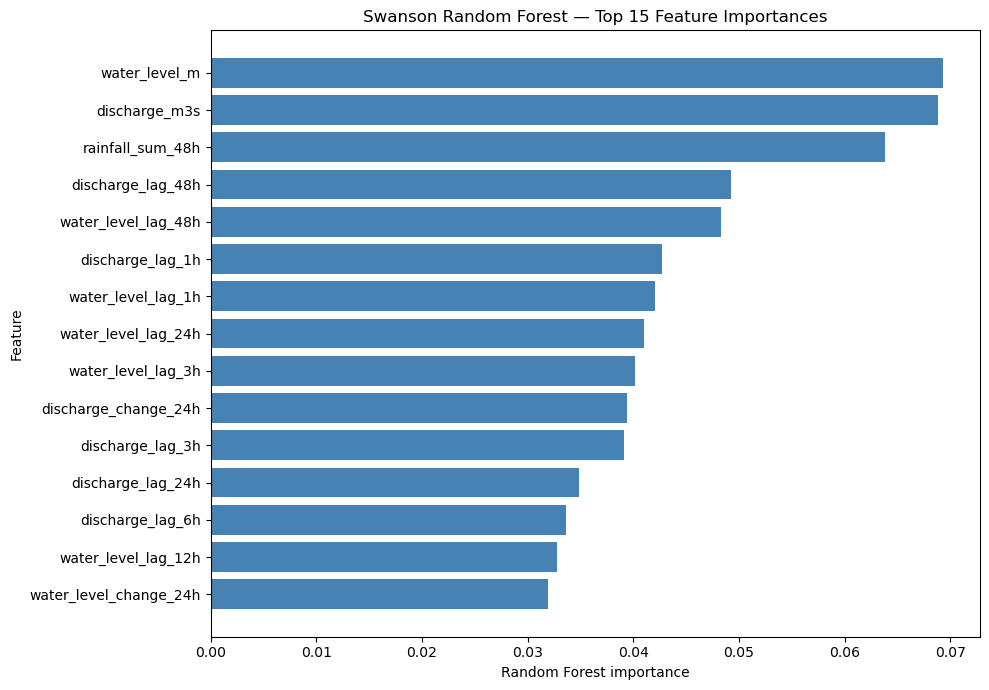

In [43]:
# RANDOM FOREST FEATURE IMPORTANCE
swanson_rf_feature_importance = (
    pd.DataFrame({
        "feature": feature_columns,
        "importance": swanson_rf.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 Swanson Random Forest features:")
display(swanson_rf_feature_importance.head(15).round(4))

# Plot top 15
top_rf_features = (
    swanson_rf_feature_importance
    .head(15)
    .sort_values("importance")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_rf_features["feature"],
    top_rf_features["importance"],
    color="steelblue"
)

plt.xlabel("Random Forest importance")
plt.ylabel("Feature")
plt.title("Swanson Random Forest — Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [44]:
# TRAIN SWANSON XGBOOST
from xgboost import XGBClassifier

# Training-only class imbalance ratio
negative_training_hours = int((y_train == 0).sum())
positive_training_hours = int((y_train == 1).sum())

swanson_scale_pos_weight = (
    negative_training_hours /
    positive_training_hours
)

print(
    "Training scale_pos_weight:",
    round(swanson_scale_pos_weight, 4)
)

swanson_xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_lambda=1.0,
    scale_pos_weight=swanson_scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Fit using training data only
swanson_xgb.fit(X_train, y_train)

# Generate training and validation probabilities only
xgb_train_probability = (
    swanson_xgb.predict_proba(X_train)[:, 1]
)

xgb_validation_probability = (
    swanson_xgb.predict_proba(X_validation)[:, 1]
)

# Threshold-independent diagnostics
xgb_probability_summary = pd.DataFrame({
    "Training": {
        "rows": len(y_train),
        "positive_hours": int(y_train.sum()),
        "ROC_AUC": roc_auc_score(
            y_train,
            xgb_train_probability
        ),
        "PR_AUC": average_precision_score(
            y_train,
            xgb_train_probability
        ),
        "minimum_probability": xgb_train_probability.min(),
        "median_probability": np.median(
            xgb_train_probability
        ),
        "maximum_probability": xgb_train_probability.max()
    },
    "Validation": {
        "rows": len(y_validation),
        "positive_hours": int(y_validation.sum()),
        "ROC_AUC": roc_auc_score(
            y_validation,
            xgb_validation_probability
        ),
        "PR_AUC": average_precision_score(
            y_validation,
            xgb_validation_probability
        ),
        "minimum_probability": xgb_validation_probability.min(),
        "median_probability": np.median(
            xgb_validation_probability
        ),
        "maximum_probability": xgb_validation_probability.max()
    }
}).T

print("\nSwanson XGBoost trained successfully.")
print("The test dataset has not been evaluated.")

display(xgb_probability_summary.round(4))

Training scale_pos_weight: 37.1238

Swanson XGBoost trained successfully.
The test dataset has not been evaluated.


,rows,positive_hours,ROC_AUC,PR_AUC,minimum_probability,median_probability,maximum_probability
Training,66526.000,1745.000,0.996,0.863,0.000,0.022,1.000
Validation,14441.000,541.000,0.740,0.341,0.000,0.046,1.000


In [45]:
# XGBOOST VALIDATION THRESHOLD SEARCH
xgb_precision_values, xgb_recall_values, xgb_probability_thresholds = (
    precision_recall_curve(
        y_validation,
        xgb_validation_probability
    )
)

xgb_threshold_results = pd.DataFrame({
    "threshold": xgb_probability_thresholds,
    "precision": xgb_precision_values[:-1],
    "recall": xgb_recall_values[:-1]
})

xgb_threshold_results["F1"] = (
    2 *
    xgb_threshold_results["precision"] *
    xgb_threshold_results["recall"] /
    (
        xgb_threshold_results["precision"] +
        xgb_threshold_results["recall"]
    )
).fillna(0)

xgb_threshold_results["F2"] = (
    5 *
    xgb_threshold_results["precision"] *
    xgb_threshold_results["recall"] /
    (
        4 * xgb_threshold_results["precision"] +
        xgb_threshold_results["recall"]
    )
).fillna(0)

# Candidate 1: highest precision while retaining at least 80% recall
xgb_recall_eligible = xgb_threshold_results[
    xgb_threshold_results["recall"] >= 0.80
].copy()

xgb_high_recall_candidate = (
    xgb_recall_eligible
    .sort_values(
        ["precision", "threshold"],
        ascending=[False, False]
    )
    .iloc[0]
)

# Candidate 2: highest validation F2
xgb_best_f2_candidate = (
    xgb_threshold_results
    .sort_values(
        ["F2", "recall", "precision"],
        ascending=False
    )
    .iloc[0]
)

xgb_candidate_thresholds = {
    "Highest precision with recall >= 0.80":
        float(xgb_high_recall_candidate["threshold"]),

    "Best validation F2":
        float(xgb_best_f2_candidate["threshold"]),

    "Standard 0.50 threshold":
        0.50
}

xgb_candidate_rows = []

for method, threshold in xgb_candidate_thresholds.items():
    predictions = (
        xgb_validation_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1]
    ).ravel()

    event_metrics = calculate_event_metrics(
        validation_data["timestamp"].to_numpy(),
        y_validation.to_numpy(),
        predictions
    )

    xgb_candidate_rows.append({
        "method": method,
        "threshold": threshold,
        "hourly_precision": precision_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "hourly_recall": recall_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "hourly_F1": f1_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "hourly_F2": fbeta_score(
            y_validation,
            predictions,
            beta=2,
            zero_division=0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "predicted_alert_hours": int(predictions.sum()),
        **event_metrics
    })

xgb_validation_candidate_comparison = (
    pd.DataFrame(xgb_candidate_rows)
    .set_index("method")
)

display(xgb_validation_candidate_comparison.round(4))

,threshold,hourly_precision,hourly_recall,hourly_F1,hourly_F2,true_positives,false_positives,false_negatives,predicted_alert_hours,events_detected,total_actual_events,event_recall,total_alert_episodes,useful_alert_episodes,false_alert_episodes,alert_episode_precision
method,,,,,,,,,,,,,,,,
Highest precision with recall >= 0.80,0.021,0.049,0.802,0.092,0.196,434,8482,107,8916,17,17,1.000,346,23,323,0.067
Best validation F2,0.653,0.261,0.357,0.301,0.332,193,547,348,740,16,17,0.941,212,31,181,0.146
Standard 0.50 threshold,0.500,0.169,0.418,0.241,0.323,226,1109,315,1335,17,17,1.000,262,33,229,0.126


In [46]:
# XGBOOST EVENT-CONSTRAINED THRESHOLD
# Highest threshold that still detects every validation event
xgb_validation_events = pd.DataFrame({
    "timestamp": validation_data["timestamp"].to_numpy(),
    "actual_risk": y_validation.to_numpy(),
    "risk_probability": xgb_validation_probability
})

xgb_validation_events["actual_episode"] = assign_episode_ids(
    xgb_validation_events["timestamp"],
    xgb_validation_events["actual_risk"]
)

# For each actual event, find the highest XGBoost probability
# produced anywhere inside that event.
event_maximum_probabilities = (
    xgb_validation_events[
        xgb_validation_events["actual_episode"] > 0
    ]
    .groupby("actual_episode")["risk_probability"]
    .max()
)

# The weakest detected event determines the highest threshold
# that can still detect all validation events.
xgb_event_recall_threshold = float(
    event_maximum_probabilities.min()
)

xgb_event_recall_prediction = (
    xgb_validation_probability >=
    xgb_event_recall_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    xgb_event_recall_prediction,
    labels=[0, 1]
).ravel()

xgb_event_recall_metrics = calculate_event_metrics(
    validation_data["timestamp"].to_numpy(),
    y_validation.to_numpy(),
    xgb_event_recall_prediction
)

xgb_event_constrained_result = pd.Series({
    "threshold": xgb_event_recall_threshold,
    "hourly_precision": precision_score(
        y_validation,
        xgb_event_recall_prediction,
        zero_division=0
    ),
    "hourly_recall": recall_score(
        y_validation,
        xgb_event_recall_prediction,
        zero_division=0
    ),
    "hourly_F1": f1_score(
        y_validation,
        xgb_event_recall_prediction,
        zero_division=0
    ),
    "hourly_F2": fbeta_score(
        y_validation,
        xgb_event_recall_prediction,
        beta=2,
        zero_division=0
    ),
    "true_positives": tp,
    "false_positives": fp,
    "false_negatives": fn,
    "predicted_alert_hours": int(
        xgb_event_recall_prediction.sum()
    ),
    **xgb_event_recall_metrics
}, name="Highest threshold with 100% event recall")

print(
    "Weakest validation event maximum probability:",
    f"{xgb_event_recall_threshold:.6f}"
)

display(
    xgb_event_constrained_result
    .to_frame("value")
    .round(4)
)

Weakest validation event maximum probability: 0.540633


,value
threshold,0.541
hourly_precision,0.185
hourly_recall,0.399
hourly_F1,0.253
hourly_F2,0.324
true_positives,216.000
false_positives,950.000
false_negatives,325.000
predicted_alert_hours,1166.000
events_detected,17.000


In [47]:
# FREEZE XGBOOST THRESHOLD AND EVALUATE TEST SET ONCE
swanson_xgb_threshold = float(
    xgb_event_recall_threshold
)

print(
    "Frozen XGBoost threshold:",
    f"{swanson_xgb_threshold:.6f}"
)

# Access untouched test data after threshold selection
xgb_test_probability = (
    swanson_xgb.predict_proba(X_test)[:, 1]
)

xgb_test_prediction = (
    xgb_test_probability >= swanson_xgb_threshold
).astype(int)

# Hour-level test metrics
tn, fp, fn, tp = confusion_matrix(
    y_test,
    xgb_test_prediction,
    labels=[0, 1]
).ravel()

xgb_test_metrics = {
    "probability_threshold": swanson_xgb_threshold,
    "flood_hour_precision": precision_score(
        y_test,
        xgb_test_prediction,
        zero_division=0
    ),
    "flood_hour_recall": recall_score(
        y_test,
        xgb_test_prediction,
        zero_division=0
    ),
    "flood_hour_F1": f1_score(
        y_test,
        xgb_test_prediction,
        zero_division=0
    ),
    "flood_hour_F2": fbeta_score(
        y_test,
        xgb_test_prediction,
        beta=2,
        zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test,
        xgb_test_probability
    ),
    "PR_AUC": average_precision_score(
        y_test,
        xgb_test_probability
    ),
    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp
}

# Event-level test metrics
xgb_test_event_metrics = calculate_event_metrics(
    test_data["timestamp"].to_numpy(),
    y_test.to_numpy(),
    xgb_test_prediction
)

xgb_final_test_summary = pd.Series({
    **xgb_test_metrics,
    **xgb_test_event_metrics
}, name="Swanson XGBoost")

display(
    xgb_final_test_summary
    .to_frame("value")
    .round(4)
)

# Preserve timestamp-level diagnostics
swanson_xgb_test_predictions = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "actual_risk": y_test.to_numpy(),
    "risk_probability": xgb_test_probability,
    "predicted_risk": xgb_test_prediction
})

print(
    "\nXGBoost test-diagnostic rows:",
    len(swanson_xgb_test_predictions)
)

display(swanson_xgb_test_predictions.head())

Frozen XGBoost threshold: 0.540633


,value
probability_threshold,0.541
flood_hour_precision,0.148
flood_hour_recall,0.446
flood_hour_F1,0.223
flood_hour_F2,0.318
ROC_AUC,0.811
PR_AUC,0.286
true_negatives,12867.000
false_positives,1132.000
false_negatives,245.000



XGBoost test-diagnostic rows: 14441


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 08:00:00,0,0.002,0
1,2024-05-08 09:00:00,0,0.001,0
2,2024-05-08 10:00:00,0,0.001,0
3,2024-05-08 11:00:00,0,0.002,0
4,2024-05-08 12:00:00,0,0.002,0


Top 15 Swanson XGBoost features:


,feature,importance
0,discharge_m3s,0.146
1,water_level_m,0.122
2,rainfall_sum_3h,0.057
3,discharge_change_24h,0.048
4,water_level_lag_24h,0.046
5,rainfall_mm,0.036
6,water_level_lag_12h,0.031
7,month_cos,0.031
8,month_sin,0.031
9,water_level_lag_48h,0.031


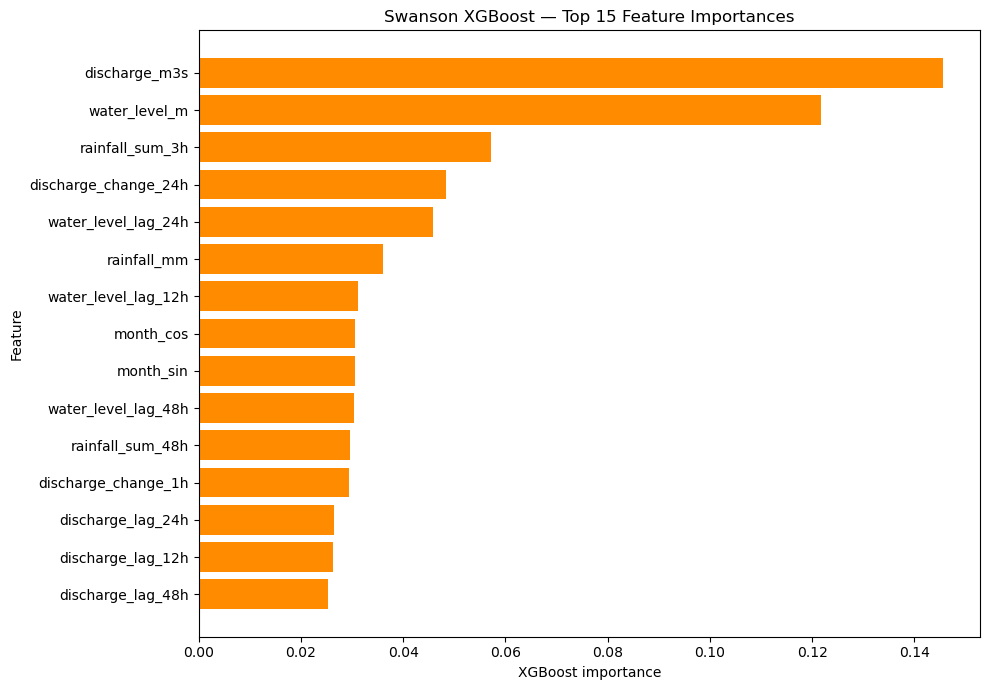

In [48]:
# XGBOOST FEATURE IMPORTANCE
swanson_xgb_feature_importance = (
    pd.DataFrame({
        "feature": feature_columns,
        "importance": swanson_xgb.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 Swanson XGBoost features:")
display(swanson_xgb_feature_importance.head(15).round(4))

top_xgb_features = (
    swanson_xgb_feature_importance
    .head(15)
    .sort_values("importance")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_xgb_features["feature"],
    top_xgb_features["importance"],
    color="darkorange"
)

plt.xlabel("XGBoost importance")
plt.ylabel("Feature")
plt.title("Swanson XGBoost — Top 15 Feature Importances")
plt.tight_layout()
plt.show()

Final untouched-test comparison:


,Random Forest,XGBoost
Probability threshold,0.115,0.541
Flood-hour precision,0.159,0.148
Flood-hour recall,0.414,0.446
Flood-hour F1,0.230,0.222
Flood-hour F2,0.314,0.318
ROC-AUC,0.830,0.811
PR-AUC,0.280,0.286
Events detected,15.000,15.000
Total actual events,15.000,15.000
Event recall,1.000,1.000


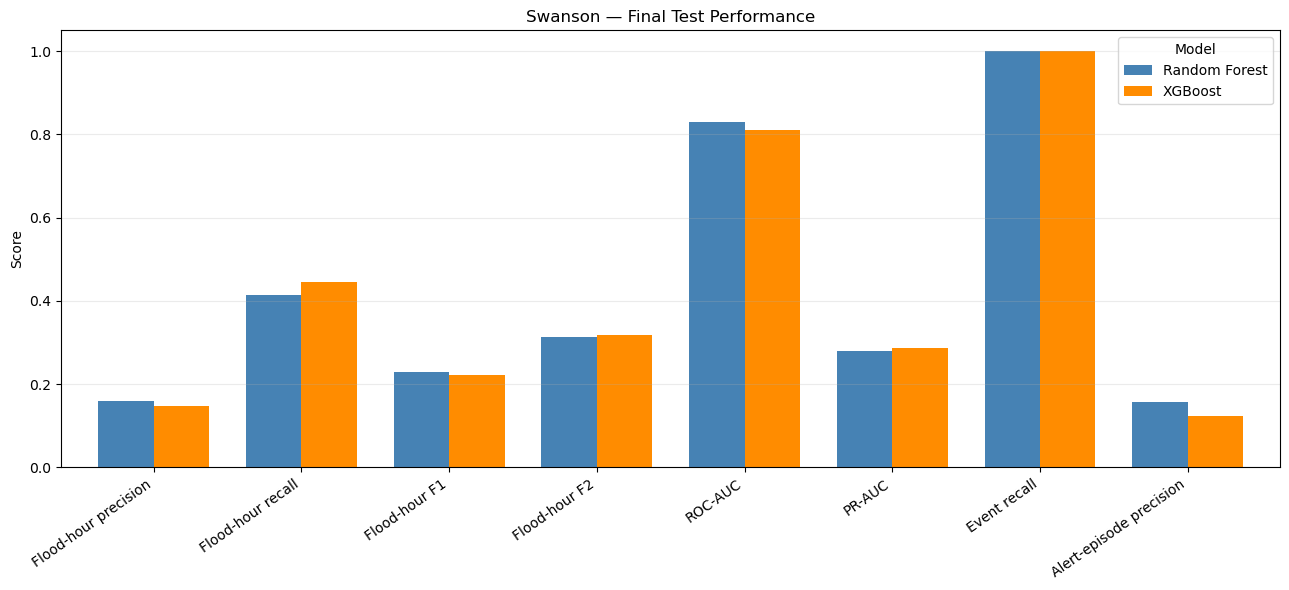

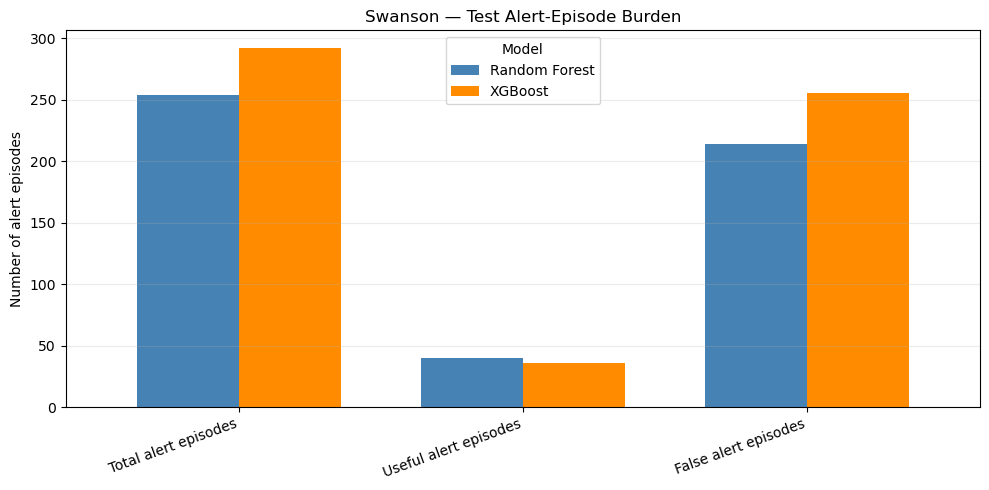

Random Forest produced 214 false alert episodes; XGBoost produced 256.
Using Random Forest reduces false alert episodes by 16.4% relative to XGBoost.

Recommended Swanson model: Random Forest — both models detected all 15 test events, but Random Forest produced fewer false-alert episodes and had higher alert-episode precision.


In [49]:
# FINAL SWANSON MODEL COMPARISON
# Uses the untouched test-set summaries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

comparison_metrics = [
    ("Probability threshold", "probability_threshold"),
    ("Flood-hour precision", "flood_hour_precision"),
    ("Flood-hour recall", "flood_hour_recall"),
    ("Flood-hour F1", "flood_hour_F1"),
    ("Flood-hour F2", "flood_hour_F2"),
    ("ROC-AUC", "ROC_AUC"),
    ("PR-AUC", "PR_AUC"),
    ("Events detected", "events_detected"),
    ("Total actual events", "total_actual_events"),
    ("Event recall", "event_recall"),
    ("Total alert episodes", "total_alert_episodes"),
    ("Useful alert episodes", "useful_alert_episodes"),
    ("False alert episodes", "false_alert_episodes"),
    ("Alert-episode precision", "alert_episode_precision"),
]

swanson_model_comparison = pd.DataFrame(
    {
        "Random Forest": [
            rf_final_test_summary[key] for _, key in comparison_metrics
        ],
        "XGBoost": [
            xgb_final_test_summary[key] for _, key in comparison_metrics
        ],
    },
    index=[label for label, _ in comparison_metrics],
)

print("Final untouched-test comparison:")
display(swanson_model_comparison.round(3))

# Score comparison
score_rows = [
    "Flood-hour precision",
    "Flood-hour recall",
    "Flood-hour F1",
    "Flood-hour F2",
    "ROC-AUC",
    "PR-AUC",
    "Event recall",
    "Alert-episode precision",
]

score_plot = swanson_model_comparison.loc[score_rows]

ax = score_plot.plot(
    kind="bar",
    figsize=(13, 6),
    color=["steelblue", "darkorange"],
    width=0.75,
)

ax.set_title("Swanson — Final Test Performance")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Alert-episode comparison
alert_rows = [
    "Total alert episodes",
    "Useful alert episodes",
    "False alert episodes",
]

alert_plot = swanson_model_comparison.loc[alert_rows]

ax = alert_plot.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
    width=0.72,
)

ax.set_title("Swanson — Test Alert-Episode Burden")
ax.set_ylabel("Number of alert episodes")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Operational interpretation
rf_false = rf_final_test_summary["false_alert_episodes"]
xgb_false = xgb_final_test_summary["false_alert_episodes"]

false_alert_reduction = 100 * (xgb_false - rf_false) / xgb_false

print(
    f"Random Forest produced {rf_false:.0f} false alert episodes; "
    f"XGBoost produced {xgb_false:.0f}."
)
print(
    f"Using Random Forest reduces false alert episodes by "
    f"{false_alert_reduction:.1f}% relative to XGBoost."
)
print()
print(
    "Recommended Swanson model: Random Forest — both models detected "
    "all 15 test events, but Random Forest produced fewer false-alert "
    "episodes and had higher alert-episode precision."
)

In [50]:
# FREEZE AND SAVE THE COMPLETE SWANSON PIPELINE
from pathlib import Path
from datetime import datetime
import json
import joblib
import pandas as pd
import numpy as np

# 1. Output folders
output_dir = Path("swanson_final_outputs")
model_dir = output_dir / "models"
data_dir = output_dir / "data"
results_dir = output_dir / "results"

for folder in [output_dir, model_dir, data_dir, results_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# 2. Save cleaned and model-ready data
swanson_clean.to_csv(
    data_dir / "swanson_cleaned_hourly_data.csv",
    index=False
)

# Save the final model-ready dataset if it exists
if "swanson_model_data" in globals():
    swanson_model_data.to_csv(
        data_dir / "swanson_model_ready_data.csv",
        index=False
    )
elif "model_data" in globals():
    model_data.to_csv(
        data_dir / "swanson_model_ready_data.csv",
        index=False
    )
else:
    print(
        "Note: model-ready dataset variable was not found; "
        "the cleaned dataset was still saved."
    )

# 3. Save trained models
joblib.dump(
    swanson_rf,
    model_dir / "swanson_random_forest.joblib"
)

joblib.dump(
    swanson_xgb,
    model_dir / "swanson_xgboost.joblib"
)

# Deployment-style bundles keep model configuration together
rf_bundle = {
    "catchment": "Swanson",
    "model_name": "Random Forest",
    "model": swanson_rf,
    "feature_columns": list(feature_columns),
    "probability_threshold": float(swanson_rf_threshold),
    "high_water_threshold_m": float(swanson_high_water_threshold),
    "forecast_horizon_hours": 24
}

xgb_bundle = {
    "catchment": "Swanson",
    "model_name": "XGBoost",
    "model": swanson_xgb,
    "feature_columns": list(feature_columns),
    "probability_threshold": float(swanson_xgb_threshold),
    "high_water_threshold_m": float(swanson_high_water_threshold),
    "forecast_horizon_hours": 24
}

joblib.dump(
    rf_bundle,
    model_dir / "swanson_random_forest_bundle.joblib"
)

joblib.dump(
    xgb_bundle,
    model_dir / "swanson_xgboost_bundle.joblib"
)

# The selected operational model
joblib.dump(
    rf_bundle,
    model_dir / "swanson_selected_model.joblib"
)

# 4. Save feature lists and feature importances
pd.DataFrame({
    "feature": list(feature_columns)
}).to_csv(
    results_dir / "swanson_model_features.csv",
    index=False
)

swanson_rf_feature_importance.to_csv(
    results_dir / "swanson_random_forest_feature_importance.csv",
    index=False
)

swanson_xgb_feature_importance.to_csv(
    results_dir / "swanson_xgboost_feature_importance.csv",
    index=False
)

# 5. Save test predictions
if "rf_test_diagnostics" in globals():
    rf_test_diagnostics.to_csv(
        results_dir / "swanson_random_forest_test_predictions.csv",
        index=False
    )
else:
    print("Note: rf_test_diagnostics was not found.")

if "xgb_test_diagnostics" in globals():
    xgb_test_diagnostics.to_csv(
        results_dir / "swanson_xgboost_test_predictions.csv",
        index=False
    )
else:
    print("Note: xgb_test_diagnostics was not found.")

# 6. Save summaries and comparison table
pd.DataFrame(
    {"value": pd.Series(rf_final_test_summary)}
).to_csv(
    results_dir / "swanson_random_forest_test_summary.csv"
)

pd.DataFrame(
    {"value": pd.Series(xgb_final_test_summary)}
).to_csv(
    results_dir / "swanson_xgboost_test_summary.csv"
)

swanson_model_comparison.to_csv(
    results_dir / "swanson_final_model_comparison.csv"
)

# 7. Save methodology and audit metadata
metadata = {
    "catchment": "Swanson",
    "created_at": datetime.now().isoformat(timespec="seconds"),

    "study_period": {
        "start": "2015-01-01 01:00:00",
        "end": "2026-01-01 00:00:00",
        "hourly_rows": 96432
    },

    "stations": {
        "primary_station": "7907",
        "discharge_support_station": "7911",
        "water_level_support_station": "7912"
    },

    "support_conversion_equations": {
        "discharge": (
            "Swanson discharge = -0.052858 "
            "+ 1.017067 × Oratia discharge"
        ),
        "water_level": (
            "Swanson water level = -0.011820 "
            "+ 0.453199 × Opanuku water level"
        )
    },

    "remaining_missing_values": {
        "rainfall_mm": 758,
        "discharge_m3s": 0,
        "water_level_m": 0
    },

    "target_definition": {
        "high_water_threshold_m": float(
            swanson_high_water_threshold
        ),
        "threshold_source": (
            "99.5th percentile of training-period water level"
        ),
        "forecast_horizon_hours": 24,
        "definition": (
            "Positive when maximum water level during "
            "t+1 to t+24 exceeds the training-derived threshold"
        )
    },

    "chronological_split": {
        "training_end": "2022-09-13 14:00:00",
        "validation_start": "2022-09-13 15:00:00",
        "validation_end": "2024-05-08 07:00:00",
        "test_start": "2024-05-08 08:00:00",
        "test_end": "2025-12-31 00:00:00"
    },

    "dataset_counts": {
        "final_model_ready_rows": 95408,
        "training_rows": 66526,
        "validation_rows": 14441,
        "test_rows": 14441,
        "number_of_features": len(feature_columns)
    },

    "models": {
        "random_forest": {
            "probability_threshold": float(
                swanson_rf_threshold
            ),
            "threshold_selection": (
                "Highest validation F2 threshold"
            )
        },
        "xgboost": {
            "probability_threshold": float(
                swanson_xgb_threshold
            ),
            "threshold_selection": (
                "Weakest validation-event maximum probability, "
                "preserving 100% validation event recall"
            )
        }
    },

    "selected_model": {
        "name": "Random Forest",
        "reason": (
            "Both models detected all 15 test events, but Random "
            "Forest produced fewer false-alert episodes and higher "
            "alert-episode precision."
        ),
        "test_events_detected": 15,
        "test_total_events": 15,
        "false_alert_episodes": 214,
        "alert_episode_precision": float(
            rf_final_test_summary["alert_episode_precision"]
        )
    },

    "data_leakage_controls": [
        "Chronological train-validation-test split",
        "High-water threshold calculated from training data only",
        "Future target constructed separately within each split",
        "Model thresholds selected using validation data only",
        "Test data evaluated once after models and thresholds were frozen",
        "Audit and source columns excluded from model predictors"
    ]
}

with open(
    output_dir / "swanson_pipeline_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=4)

# 8. Create and display file manifest
saved_files = sorted(
    path for path in output_dir.rglob("*") if path.is_file()
)

manifest = pd.DataFrame({
    "file": [
        str(path.relative_to(output_dir))
        for path in saved_files
    ],
    "size_kb": [
        round(path.stat().st_size / 1024, 2)
        for path in saved_files
    ]
})

manifest.to_csv(
    output_dir / "swanson_output_manifest.csv",
    index=False
)

print("Swanson pipeline frozen successfully.")
print(f"Selected model: Random Forest")
print(f"Output folder: {output_dir.resolve()}")
print(f"Files saved: {len(saved_files) + 1}")

display(manifest)

Note: rf_test_diagnostics was not found.
Note: xgb_test_diagnostics was not found.
Swanson pipeline frozen successfully.
Selected model: Random Forest
Output folder: C:\Users\kgeet\swanson_final_outputs
Files saved: 18


,file,size_kb
0,data\swanson_cleaned_hourly_data.csv,13091.210
1,data\swanson_model_ready_data.csv,14843.430
2,models\swanson_random_forest.joblib,50183.010
3,models\swanson_random_forest_bundle.joblib,50183.730
4,models\swanson_selected_model.joblib,50183.730
5,models\swanson_xgboost.joblib,792.670
6,models\swanson_xgboost_bundle.joblib,793.400
7,results\swanson_final_model_comparison.csv,0.640
8,results\swanson_model_features.csv,0.540
9,results\swanson_random_forest_feature_importan...,1.140


In [51]:
# Find variables containing test timestamps, labels,
# probabilities, or predictions

candidate_words = [
    "test", "prob", "pred", "actual",
    "risk", "target", "timestamp"
]

candidate_variables = []

# list(...) freezes a copy before iteration
for variable_name, variable_value in list(globals().items()):
    if any(
        word in variable_name.lower()
        for word in candidate_words
    ):
        try:
            variable_shape = variable_value.shape
        except Exception:
            variable_shape = None

        candidate_variables.append({
            "variable": variable_name,
            "type": type(variable_value).__name__,
            "shape": str(variable_shape)
        })

candidate_variables = pd.DataFrame(candidate_variables)

candidate_variables["likely_test_object"] = (
    candidate_variables["shape"]
    .str.contains("14441", na=False)
)

candidate_variables = (
    candidate_variables
    .sort_values(
        ["likely_test_object", "variable"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(candidate_variables)

,variable,type,shape,likely_test_object
0,X_test,DataFrame,"(14441, 30)",True
1,predicted,ndarray,"(14441,)",True
2,predictions,ndarray,"(14441,)",True
3,rf_test_prediction,ndarray,"(14441,)",True
4,rf_test_probability,ndarray,"(14441,)",True
5,rf_validation_probability,ndarray,"(14441,)",True
6,swanson_rf_test_predictions,DataFrame,"(14441, 4)",True
7,swanson_xgb_test_predictions,DataFrame,"(14441, 4)",True
8,test_data,DataFrame,"(14441, 47)",True
9,xgb_event_recall_prediction,ndarray,"(14441,)",True


In [52]:
# SAVE THE EXISTING TEST-PREDICTION TABLES
from pathlib import Path
import pandas as pd

output_dir = Path("swanson_final_outputs")
results_dir = output_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

rf_prediction_path = (
    results_dir /
    "swanson_random_forest_test_predictions.csv"
)

xgb_prediction_path = (
    results_dir /
    "swanson_xgboost_test_predictions.csv"
)

swanson_rf_test_predictions.to_csv(
    rf_prediction_path,
    index=False
)

swanson_xgb_test_predictions.to_csv(
    xgb_prediction_path,
    index=False
)

# Validate the saved prediction tables
assert len(swanson_rf_test_predictions) == 14441
assert len(swanson_xgb_test_predictions) == 14441

assert swanson_rf_test_predictions.isna().sum().sum() == 0
assert swanson_xgb_test_predictions.isna().sum().sum() == 0

print("Random Forest test predictions saved:")
print(rf_prediction_path.resolve())
display(swanson_rf_test_predictions.head())

print("\nXGBoost test predictions saved:")
print(xgb_prediction_path.resolve())
display(swanson_xgb_test_predictions.head())

# Refresh the complete manifest
saved_files = sorted(
    path for path in output_dir.rglob("*")
    if path.is_file()
    and path.name != "swanson_output_manifest.csv"
)

manifest = pd.DataFrame({
    "file": [
        str(path.relative_to(output_dir))
        for path in saved_files
    ],
    "size_kb": [
        round(path.stat().st_size / 1024, 2)
        for path in saved_files
    ]
})

manifest_path = output_dir / "swanson_output_manifest.csv"

manifest.to_csv(
    manifest_path,
    index=False
)

print("\nSwanson pipeline is now fully frozen.")
print(f"Prediction rows per model: {len(swanson_rf_test_predictions)}")
print(f"Total saved files, including manifest: {len(saved_files) + 1}")

display(manifest)

Random Forest test predictions saved:
C:\Users\kgeet\swanson_final_outputs\results\swanson_random_forest_test_predictions.csv


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 08:00:00,0,0.000,0
1,2024-05-08 09:00:00,0,0.000,0
2,2024-05-08 10:00:00,0,0.000,0
3,2024-05-08 11:00:00,0,0.000,0
4,2024-05-08 12:00:00,0,0.000,0



XGBoost test predictions saved:
C:\Users\kgeet\swanson_final_outputs\results\swanson_xgboost_test_predictions.csv


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 08:00:00,0,0.002,0
1,2024-05-08 09:00:00,0,0.001,0
2,2024-05-08 10:00:00,0,0.001,0
3,2024-05-08 11:00:00,0,0.002,0
4,2024-05-08 12:00:00,0,0.002,0



Swanson pipeline is now fully frozen.
Prediction rows per model: 14441
Total saved files, including manifest: 17


,file,size_kb
0,data\swanson_cleaned_hourly_data.csv,13091.210
1,data\swanson_model_ready_data.csv,14843.430
2,models\swanson_random_forest.joblib,50183.010
3,models\swanson_random_forest_bundle.joblib,50183.730
4,models\swanson_selected_model.joblib,50183.730
5,models\swanson_xgboost.joblib,792.670
6,models\swanson_xgboost_bundle.joblib,793.400
7,results\swanson_final_model_comparison.csv,0.640
8,results\swanson_model_features.csv,0.540
9,results\swanson_random_forest_feature_importan...,1.140


In [53]:
# PREPARE SWANSON DATA FOR GAUSSIAN NAIVE BAYES

from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

required_objects = [
    "X_train",
    "y_train",
    "X_validation",
    "y_validation",
    "X_test",
    "y_test"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Run the model-ready dataset cell first. Missing: {missing_objects}"
    )

for split_name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_validation, y_validation),
    ("Test", X_test, y_test)
]:
    assert X.shape[1] == len(feature_columns)
    assert not X.isna().any().any()
    assert not y.isna().any()
    assert set(y.unique()).issubset({0, 1})

    print(
        f"{split_name}: {X.shape[0]} rows, "
        f"{X.shape[1]} features, "
        f"{int(y.sum())} high-risk rows"
    )

Training: 66526 rows, 30 features, 1745 high-risk rows
Validation: 14441 rows, 30 features, 541 high-risk rows
Test: 14441 rows, 30 features, 442 high-risk rows


In [54]:
# TUNE SWANSON GAUSSIAN NAIVE BAYES

from sklearn.metrics import (
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

var_smoothing_values = np.logspace(-12, 8, 41)
naive_bayes_tuning_rows = []

for var_smoothing in var_smoothing_values:

    candidate_model = Pipeline([
        ("scaler", StandardScaler()),
        ("naive_bayes", GaussianNB(
            var_smoothing=var_smoothing
        ))
    ])

    candidate_model.fit(X_train, y_train)

    validation_probability = (
        candidate_model.predict_proba(X_validation)[:, 1]
    )

    precision, recall, thresholds = precision_recall_curve(
        y_validation,
        validation_probability
    )

    f2_scores = (
        5 * precision[:-1] * recall[:-1] /
        (4 * precision[:-1] + recall[:-1] + 1e-12)
    )

    best_index = np.argmax(f2_scores)

    naive_bayes_tuning_rows.append({
        "var_smoothing": var_smoothing,
        "selected_threshold": thresholds[best_index],
        "validation_precision": precision[best_index],
        "validation_recall": recall[best_index],
        "validation_f2": f2_scores[best_index],
        "validation_roc_auc": roc_auc_score(
            y_validation,
            validation_probability
        ),
        "validation_pr_auc": average_precision_score(
            y_validation,
            validation_probability
        )
    })

swanson_naive_bayes_tuning_results = (
    pd.DataFrame(naive_bayes_tuning_rows)
    .sort_values(
        ["validation_f2", "validation_pr_auc"],
        ascending=False
    )
    .reset_index(drop=True)
)

best_naive_bayes_result = (
    swanson_naive_bayes_tuning_results.iloc[0]
)

selected_var_smoothing = float(
    best_naive_bayes_result["var_smoothing"]
)

selected_probability_threshold = float(
    best_naive_bayes_result["selected_threshold"]
)

print(
    "Selected var_smoothing:",
    f"{selected_var_smoothing:.6e}"
)

print(
    "Selected probability threshold:",
    f"{selected_probability_threshold:.6e}"
)

print(
    "Maximum validation F2:",
    f"{best_naive_bayes_result['validation_f2']:.4f}"
)

display(
    swanson_naive_bayes_tuning_results
    .head(10)
    .round(4)
)

Selected var_smoothing: 1.000000e+05
Selected probability threshold: 2.619302e-02
Maximum validation F2: 0.4240


,var_smoothing,selected_threshold,validation_precision,validation_recall,validation_f2,validation_roc_auc,validation_pr_auc
0,100000.000,0.026,0.206,0.577,0.424,0.855,0.427
1,316227.766,0.026,0.206,0.577,0.424,0.855,0.427
2,1000000.000,0.026,0.206,0.577,0.424,0.855,0.427
3,3162277.660,0.026,0.206,0.577,0.424,0.855,0.427
4,31622776.602,0.026,0.206,0.577,0.424,0.855,0.427
5,10000000.000,0.026,0.206,0.577,0.424,0.855,0.427
6,100000000.000,0.026,0.206,0.577,0.424,0.855,0.427
7,31622.777,0.026,0.206,0.577,0.424,0.855,0.427
8,10000.000,0.026,0.206,0.577,0.424,0.855,0.427
9,3162.278,0.025,0.206,0.577,0.424,0.855,0.427


In [55]:
# FIT FINAL SWANSON GAUSSIAN NAIVE BAYES MODEL

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

swanson_naive_bayes_model = Pipeline([
    ("scaler", StandardScaler()),
    ("naive_bayes", GaussianNB(
        var_smoothing=selected_var_smoothing
    ))
])

swanson_naive_bayes_model.fit(X_train, y_train)

training_probability_nb = (
    swanson_naive_bayes_model.predict_proba(X_train)[:, 1]
)

validation_probability_nb = (
    swanson_naive_bayes_model.predict_proba(X_validation)[:, 1]
)

validation_prediction_nb = (
    validation_probability_nb >= selected_probability_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    validation_prediction_nb,
    labels=[0, 1]
).ravel()

swanson_naive_bayes_validation_results = pd.Series({
    "selected_threshold": selected_probability_threshold,
    "accuracy": accuracy_score(
        y_validation,
        validation_prediction_nb
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_validation,
        validation_prediction_nb
    ),
    "precision": precision_score(
        y_validation,
        validation_prediction_nb,
        zero_division=0
    ),
    "recall": recall_score(
        y_validation,
        validation_prediction_nb,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_validation,
        validation_prediction_nb,
        zero_division=0
    ),
    "f2_score": fbeta_score(
        y_validation,
        validation_prediction_nb,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_validation,
        validation_probability_nb
    ),
    "pr_auc": average_precision_score(
        y_validation,
        validation_probability_nb
    ),
    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp
}, name="value")

print("Swanson Gaussian Naive Bayes fitted successfully.")

display(
    swanson_naive_bayes_validation_results
    .to_frame()
    .round(4)
)

Swanson Gaussian Naive Bayes fitted successfully.


,value
selected_threshold,0.026
accuracy,0.901
balanced_accuracy,0.745
precision,0.206
recall,0.577
f1_score,0.303
f2_score,0.424
roc_auc,0.855
pr_auc,0.427
true_negatives,12697.000


,Predicted normal,Predicted high risk
Actual normal,12697,1203
Actual high risk,229,312



Validation classification report:

              precision    recall  f1-score   support

      Normal     0.9823    0.9135    0.9466     13900
   High risk     0.2059    0.5767    0.3035       541

    accuracy                         0.9008     14441
   macro avg     0.5941    0.7451    0.6251     14441
weighted avg     0.9532    0.9008    0.9225     14441



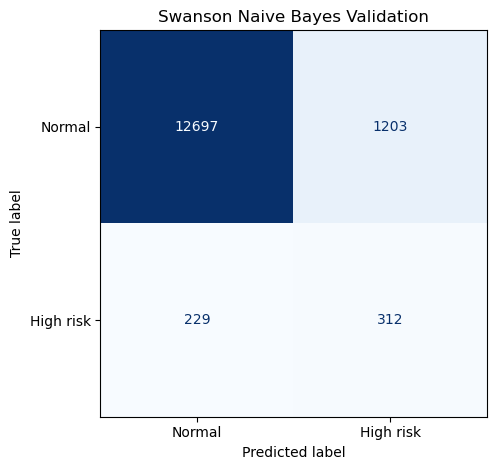

In [56]:
# SWANSON NAIVE BAYES VALIDATION CONFUSION MATRIX

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report
)

swanson_naive_bayes_validation_confusion = confusion_matrix(
    y_validation,
    validation_prediction_nb,
    labels=[0, 1]
)

display(
    pd.DataFrame(
        swanson_naive_bayes_validation_confusion,
        index=["Actual normal", "Actual high risk"],
        columns=["Predicted normal", "Predicted high risk"]
    )
)

print("\nValidation classification report:\n")

print(
    classification_report(
        y_validation,
        validation_prediction_nb,
        target_names=["Normal", "High risk"],
        digits=4,
        zero_division=0
    )
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=swanson_naive_bayes_validation_confusion,
    display_labels=["Normal", "High risk"]
)

display_plot.plot(
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Swanson Naive Bayes Validation")
plt.tight_layout()
plt.show()

In [57]:
# EVALUATE SWANSON NAIVE BAYES ON THE UNTOUCHED TEST SET

test_probability_nb = (
    swanson_naive_bayes_model.predict_proba(X_test)[:, 1]
)

test_prediction_nb = (
    test_probability_nb >= selected_probability_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_prediction_nb,
    labels=[0, 1]
).ravel()

swanson_naive_bayes_test_results = pd.Series({
    "var_smoothing": selected_var_smoothing,
    "selected_threshold": selected_probability_threshold,
    "rows": len(y_test),
    "actual_high_risk": int(y_test.sum()),
    "predicted_high_risk": int(test_prediction_nb.sum()),
    "accuracy": accuracy_score(
        y_test,
        test_prediction_nb
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test,
        test_prediction_nb
    ),
    "precision": precision_score(
        y_test,
        test_prediction_nb,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        test_prediction_nb,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_test,
        test_prediction_nb,
        zero_division=0
    ),
    "f2_score": fbeta_score(
        y_test,
        test_prediction_nb,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        test_probability_nb
    ),
    "pr_auc": average_precision_score(
        y_test,
        test_probability_nb
    ),
    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp
}, name="value")

swanson_naive_bayes_test_predictions = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "observed_high_water_risk_24h": y_test.to_numpy(),
    "naive_bayes_score": test_probability_nb,
    "predicted_high_water_risk_24h": test_prediction_nb,
    "rainfall_mm": test_data["rainfall_mm"].to_numpy(),
    "discharge_m3s": test_data["discharge_m3s"].to_numpy(),
    "water_level_m": test_data["water_level_m"].to_numpy()
})

print("SWANSON GAUSSIAN NAIVE BAYES FINAL TEST RESULTS")

display(
    swanson_naive_bayes_test_results
    .to_frame()
    .round(4)
)

print("\nTest prediction rows:", len(
    swanson_naive_bayes_test_predictions
))

display(swanson_naive_bayes_test_predictions.head())

SWANSON GAUSSIAN NAIVE BAYES FINAL TEST RESULTS


,value
var_smoothing,100000.000
selected_threshold,0.026
rows,14441.000
actual_high_risk,442.000
predicted_high_risk,1354.000
accuracy,0.905
balanced_accuracy,0.698
precision,0.156
recall,0.477
f1_score,0.235



Test prediction rows: 14441


,timestamp,observed_high_water_risk_24h,naive_bayes_score,predicted_high_water_risk_24h,rainfall_mm,discharge_m3s,water_level_m
0,2024-05-08 08:00:00,0,0.026,0,0.000,0.108,0.293
1,2024-05-08 09:00:00,0,0.026,0,0.000,0.107,0.292
2,2024-05-08 10:00:00,0,0.026,0,0.000,0.107,0.292
3,2024-05-08 11:00:00,0,0.026,0,0.000,0.108,0.293
4,2024-05-08 12:00:00,0,0.026,0,0.000,0.107,0.292


,Predicted normal,Predicted high risk
Actual normal,12856,1143
Actual high risk,231,211



Test classification report:

              precision    recall  f1-score   support

      Normal     0.9823    0.9184    0.9493     13999
   High risk     0.1558    0.4774    0.2350       442

    accuracy                         0.9049     14441
   macro avg     0.5691    0.6979    0.5921     14441
weighted avg     0.9571    0.9049    0.9274     14441



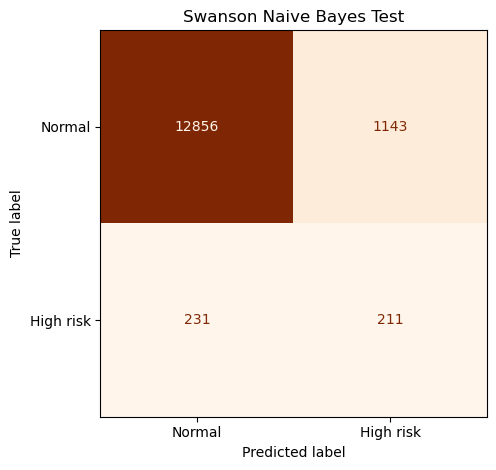

In [58]:
# SWANSON NAIVE BAYES TEST CONFUSION MATRIX

swanson_naive_bayes_test_confusion = confusion_matrix(
    y_test,
    test_prediction_nb,
    labels=[0, 1]
)

display(
    pd.DataFrame(
        swanson_naive_bayes_test_confusion,
        index=["Actual normal", "Actual high risk"],
        columns=["Predicted normal", "Predicted high risk"]
    )
)

print("\nTest classification report:\n")

print(
    classification_report(
        y_test,
        test_prediction_nb,
        target_names=["Normal", "High risk"],
        digits=4,
        zero_division=0
    )
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=swanson_naive_bayes_test_confusion,
    display_labels=["Normal", "High risk"]
)

display_plot.plot(
    cmap="Oranges",
    values_format="d",
    colorbar=False
)

plt.title("Swanson Naive Bayes Test")
plt.tight_layout()
plt.show()

In [59]:
# SWANSON NAIVE BAYES EVENT-LEVEL TEST RESULTS

swanson_naive_bayes_event_metrics = calculate_event_metrics(
    test_data["timestamp"].to_numpy(),
    y_test.to_numpy(),
    test_prediction_nb
)

swanson_naive_bayes_event_summary = pd.Series(
    swanson_naive_bayes_event_metrics,
    name="value"
)

event_evaluation_nb = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "actual_risk": y_test.to_numpy(),
    "predicted_risk": test_prediction_nb,
    "naive_bayes_score": test_probability_nb,
    "water_level_m": test_data["water_level_m"].to_numpy()
})

event_evaluation_nb["event_id"] = assign_episode_ids(
    event_evaluation_nb["timestamp"],
    event_evaluation_nb["actual_risk"]
)

event_rows = []

for event_id, event_data in (
    event_evaluation_nb[
        event_evaluation_nb["event_id"] > 0
    ].groupby("event_id")
):
    detected_hours = int(
        event_data["predicted_risk"].sum()
    )

    event_hours = len(event_data)

    event_rows.append({
        "event_id": int(event_id),
        "event_start": event_data["timestamp"].min(),
        "event_end": event_data["timestamp"].max(),
        "event_hours": event_hours,
        "detected_hours": detected_hours,
        "maximum_naive_bayes_score":
            event_data["naive_bayes_score"].max(),
        "mean_naive_bayes_score":
            event_data["naive_bayes_score"].mean(),
        "maximum_water_level_m":
            event_data["water_level_m"].max(),
        "event_detected": detected_hours > 0,
        "hourly_detection_percentage":
            100 * detected_hours / event_hours
    })

swanson_naive_bayes_event_results = pd.DataFrame(
    event_rows
)

print(
    "Physical high-risk events:",
    swanson_naive_bayes_event_metrics["total_actual_events"]
)

print(
    "Events detected:",
    swanson_naive_bayes_event_metrics["events_detected"]
)

print(
    "Event-level recall:",
    f"{swanson_naive_bayes_event_metrics['event_recall']:.3f}"
)

display(
    swanson_naive_bayes_event_results.round(4)
)

Physical high-risk events: 15
Events detected: 15
Event-level recall: 1.000


,event_id,event_start,event_end,event_hours,detected_hours,maximum_naive_bayes_score,mean_naive_bayes_score,maximum_water_level_m,event_detected,hourly_detection_percentage
0,1,2024-06-13 08:00:00,2024-06-14 08:00:00,25,8,0.026,0.026,1.131,True,32.000
1,2,2024-08-31 04:00:00,2024-09-01 05:00:00,26,12,0.026,0.026,1.177,True,46.154
2,3,2025-04-19 19:00:00,2025-04-20 18:00:00,24,18,0.026,0.026,1.083,True,75.000
3,4,2025-05-01 13:00:00,2025-05-02 14:00:00,26,19,0.026,0.026,1.158,True,73.077
4,5,2025-05-08 18:00:00,2025-05-09 19:00:00,26,16,0.026,0.026,1.132,True,61.538
5,6,2025-06-09 21:00:00,2025-06-11 01:00:00,29,19,0.026,0.026,1.461,True,65.517
6,7,2025-06-26 11:00:00,2025-06-27 11:00:00,25,4,0.026,0.026,1.136,True,16.000
7,8,2025-07-09 12:00:00,2025-07-11 21:00:00,58,36,0.026,0.026,1.699,True,62.069
8,9,2025-07-16 08:00:00,2025-07-17 17:00:00,34,13,0.026,0.026,1.181,True,38.235
9,10,2025-07-28 13:00:00,2025-07-30 01:00:00,37,20,0.026,0.026,1.397,True,54.054


In [60]:
# SWANSON NAIVE BAYES ALERT-EPISODE RESULTS

alert_evaluation_nb = event_evaluation_nb.copy()

alert_evaluation_nb["alert_id"] = assign_episode_ids(
    alert_evaluation_nb["timestamp"],
    alert_evaluation_nb["predicted_risk"]
)

alert_rows = []

for alert_id, alert_data in (
    alert_evaluation_nb[
        alert_evaluation_nb["alert_id"] > 0
    ].groupby("alert_id")
):
    alert_rows.append({
        "alert_id": int(alert_id),
        "alert_start": alert_data["timestamp"].min(),
        "alert_end": alert_data["timestamp"].max(),
        "alert_hours": len(alert_data),
        "actual_risk_hours": int(
            alert_data["actual_risk"].sum()
        ),
        "maximum_naive_bayes_score":
            alert_data["naive_bayes_score"].max(),
        "mean_naive_bayes_score":
            alert_data["naive_bayes_score"].mean(),
        "associated_with_risk":
            bool(alert_data["actual_risk"].eq(1).any())
    })

swanson_naive_bayes_alert_results = pd.DataFrame(
    alert_rows
)

total_alert_episodes = len(
    swanson_naive_bayes_alert_results
)

risk_associated_alert_episodes = int(
    swanson_naive_bayes_alert_results[
        "associated_with_risk"
    ].sum()
)

false_alert_episodes = (
    total_alert_episodes -
    risk_associated_alert_episodes
)

alert_episode_precision = (
    risk_associated_alert_episodes /
    total_alert_episodes
    if total_alert_episodes else 0
)

print(
    "Total predicted alert episodes:",
    total_alert_episodes
)

print(
    "Risk-associated alert episodes:",
    risk_associated_alert_episodes
)

print(
    "False alert episodes:",
    false_alert_episodes
)

print(
    "Alert-episode precision:",
    f"{alert_episode_precision:.3f}"
)

display(
    swanson_naive_bayes_alert_results.round({
        "maximum_naive_bayes_score": 8,
        "mean_naive_bayes_score": 8
    })
)

Total predicted alert episodes: 143
Risk-associated alert episodes: 25
False alert episodes: 118
Alert-episode precision: 0.175


,alert_id,alert_start,alert_end,alert_hours,actual_risk_hours,maximum_naive_bayes_score,mean_naive_bayes_score,associated_with_risk
0,1,2024-05-15 05:00:00,2024-05-15 12:00:00,8,0,0.026,0.026,False
1,2,2024-05-20 20:00:00,2024-05-21 09:00:00,14,0,0.026,0.026,False
2,3,2024-05-21 11:00:00,2024-05-21 19:00:00,9,0,0.026,0.026,False
3,4,2024-05-21 22:00:00,2024-05-22 00:00:00,3,0,0.026,0.026,False
4,5,2024-05-24 15:00:00,2024-05-24 15:00:00,1,0,0.026,0.026,False
...,...,...,...,...,...,...,...,...
138,139,2025-12-02 12:00:00,2025-12-02 12:00:00,1,0,0.026,0.026,False
139,140,2025-12-03 18:00:00,2025-12-03 18:00:00,1,0,0.026,0.026,False
140,141,2025-12-16 18:00:00,2025-12-16 18:00:00,1,0,0.026,0.026,False
141,142,2025-12-24 08:00:00,2025-12-24 09:00:00,2,0,0.026,0.026,False


In [61]:
# SWANSON NAIVE BAYES TRAINING AND TEST PERFORMANCE

training_prediction_nb = (
    training_probability_nb >= selected_probability_threshold
).astype(int)

swanson_naive_bayes_train_test_comparison = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(
            y_train,
            training_prediction_nb
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_train,
            training_prediction_nb
        ),
        "Precision": precision_score(
            y_train,
            training_prediction_nb,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train,
            training_prediction_nb,
            zero_division=0
        ),
        "F1": f1_score(
            y_train,
            training_prediction_nb,
            zero_division=0
        ),
        "F2": fbeta_score(
            y_train,
            training_prediction_nb,
            beta=2,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_train,
            training_probability_nb
        ),
        "PR-AUC": average_precision_score(
            y_train,
            training_probability_nb
        )
    },
    "Test": {
        "Accuracy": accuracy_score(
            y_test,
            test_prediction_nb
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_test,
            test_prediction_nb
        ),
        "Precision": precision_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
        "F2": fbeta_score(
            y_test,
            test_prediction_nb,
            beta=2,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            test_probability_nb
        ),
        "PR-AUC": average_precision_score(
            y_test,
            test_probability_nb
        )
    }
})

print(
    "SWANSON NAIVE BAYES TRAINING VERSUS TEST PERFORMANCE"
)

display(
    swanson_naive_bayes_train_test_comparison.round(4)
)

SWANSON NAIVE BAYES TRAINING VERSUS TEST PERFORMANCE


,Training,Test
Accuracy,0.907,0.905
Balanced accuracy,0.687,0.698
Precision,0.131,0.156
Recall,0.455,0.477
F1,0.204,0.235
F2,0.304,0.338
ROC-AUC,0.818,0.803
PR-AUC,0.319,0.267


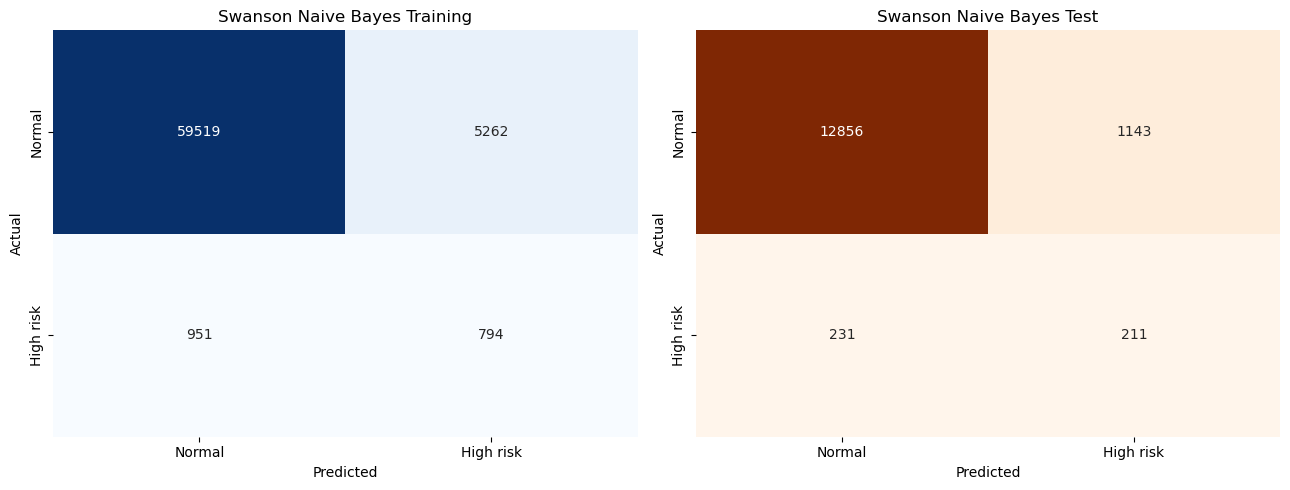

In [62]:
# SWANSON NAIVE BAYES TRAINING AND TEST CONFUSION MATRICES

swanson_naive_bayes_training_confusion = confusion_matrix(
    y_train,
    training_prediction_nb,
    labels=[0, 1]
)

swanson_naive_bayes_test_confusion = confusion_matrix(
    y_test,
    test_prediction_nb,
    labels=[0, 1]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

sns.heatmap(
    swanson_naive_bayes_training_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"],
    ax=axes[0]
)

axes[0].set_title("Swanson Naive Bayes Training")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    swanson_naive_bayes_test_confusion,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"],
    ax=axes[1]
)

axes[1].set_title("Swanson Naive Bayes Test")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

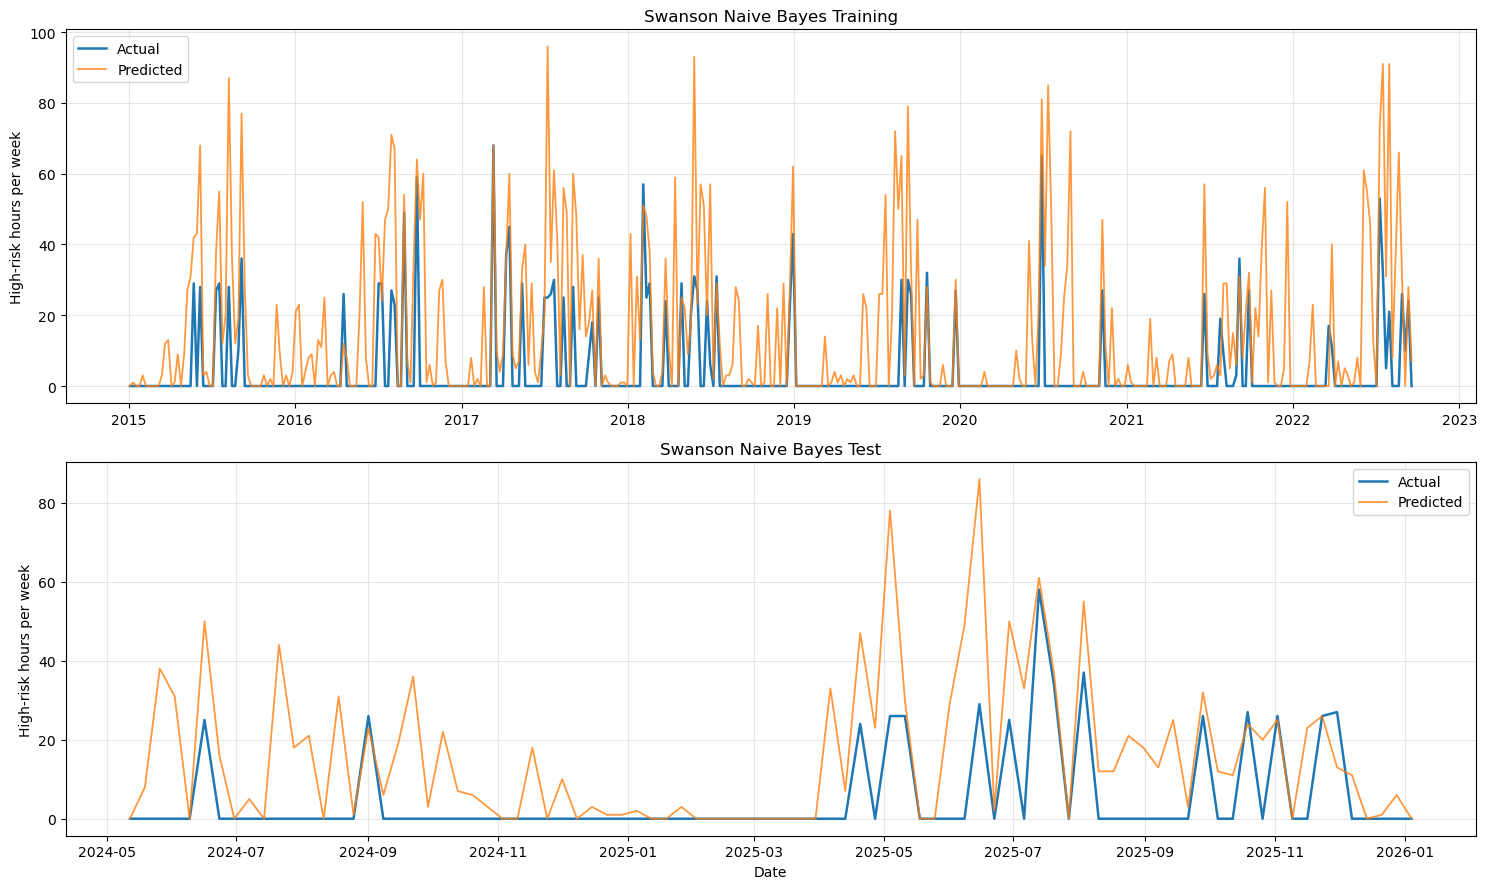

In [63]:
# SWANSON NAIVE BAYES ACTUAL VERSUS PREDICTED RISK HOURS

training_weekly_nb = pd.DataFrame({
    "timestamp": train_data["timestamp"].to_numpy(),
    "Actual": y_train.to_numpy(),
    "Predicted": training_prediction_nb
})

training_weekly_nb["timestamp"] = pd.to_datetime(
    training_weekly_nb["timestamp"]
)

training_weekly_nb = (
    training_weekly_nb
    .set_index("timestamp")
    .resample("W")
    .sum()
)

test_weekly_nb = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": test_prediction_nb
})

test_weekly_nb["timestamp"] = pd.to_datetime(
    test_weekly_nb["timestamp"]
)

test_weekly_nb = (
    test_weekly_nb
    .set_index("timestamp")
    .resample("W")
    .sum()
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 9)
)

axes[0].plot(
    training_weekly_nb.index,
    training_weekly_nb["Actual"],
    label="Actual",
    linewidth=1.8
)

axes[0].plot(
    training_weekly_nb.index,
    training_weekly_nb["Predicted"],
    label="Predicted",
    linewidth=1.3,
    alpha=0.8
)

axes[0].set_title("Swanson Naive Bayes Training")
axes[0].set_ylabel("High-risk hours per week")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    test_weekly_nb.index,
    test_weekly_nb["Actual"],
    label="Actual",
    linewidth=1.8
)

axes[1].plot(
    test_weekly_nb.index,
    test_weekly_nb["Predicted"],
    label="Predicted",
    linewidth=1.3,
    alpha=0.8
)

axes[1].set_title("Swanson Naive Bayes Test")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("High-risk hours per week")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [64]:
# SWANSON FINAL TEST COMPARISON FOR ALL THREE MODELS

def build_model_comparison(
    probability,
    prediction,
    threshold
):
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction,
        labels=[0, 1]
    ).ravel()

    event_metrics = calculate_event_metrics(
        test_data["timestamp"].to_numpy(),
        y_test.to_numpy(),
        prediction
    )

    return {
        "Probability threshold": threshold,
        "Accuracy": accuracy_score(
            y_test,
            prediction
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_test,
            prediction
        ),
        "Flood-hour precision": precision_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "Flood-hour recall": recall_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "Flood-hour F1": f1_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "Flood-hour F2": fbeta_score(
            y_test,
            prediction,
            beta=2,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probability
        ),
        "PR-AUC": average_precision_score(
            y_test,
            probability
        ),
        "True positives": tp,
        "False negatives": fn,
        "False positives": fp,
        "True negatives": tn,
        "Events detected":
            event_metrics["events_detected"],
        "Total actual events":
            event_metrics["total_actual_events"],
        "Event-level recall":
            event_metrics["event_recall"],
        "Total alert episodes":
            event_metrics["total_alert_episodes"],
        "Useful alert episodes":
            event_metrics["useful_alert_episodes"],
        "False alert episodes":
            event_metrics["false_alert_episodes"],
        "Alert-episode precision":
            event_metrics["alert_episode_precision"]
    }


random_forest_comparison = build_model_comparison(
    rf_test_probability,
    rf_test_prediction,
    swanson_rf_threshold
)

xgboost_comparison = build_model_comparison(
    xgb_test_probability,
    xgb_test_prediction,
    swanson_xgb_threshold
)

naive_bayes_comparison = build_model_comparison(
    test_probability_nb,
    test_prediction_nb,
    selected_probability_threshold
)

swanson_three_model_test_comparison = pd.DataFrame({
    "Random Forest": random_forest_comparison,
    "XGBoost": xgboost_comparison,
    "Naive Bayes": naive_bayes_comparison
})

print("SWANSON FINAL TEST MODEL COMPARISON")

display(
    swanson_three_model_test_comparison.round(4)
)

SWANSON FINAL TEST MODEL COMPARISON


,Random Forest,XGBoost,Naive Bayes
Probability threshold,0.115,0.541,0.026
Accuracy,0.915,0.905,0.905
Balanced accuracy,0.672,0.682,0.698
Flood-hour precision,0.159,0.148,0.156
Flood-hour recall,0.414,0.446,0.477
Flood-hour F1,0.230,0.223,0.235
Flood-hour F2,0.314,0.318,0.338
ROC-AUC,0.830,0.811,0.803
PR-AUC,0.280,0.286,0.267
True positives,183.000,197.000,211.000


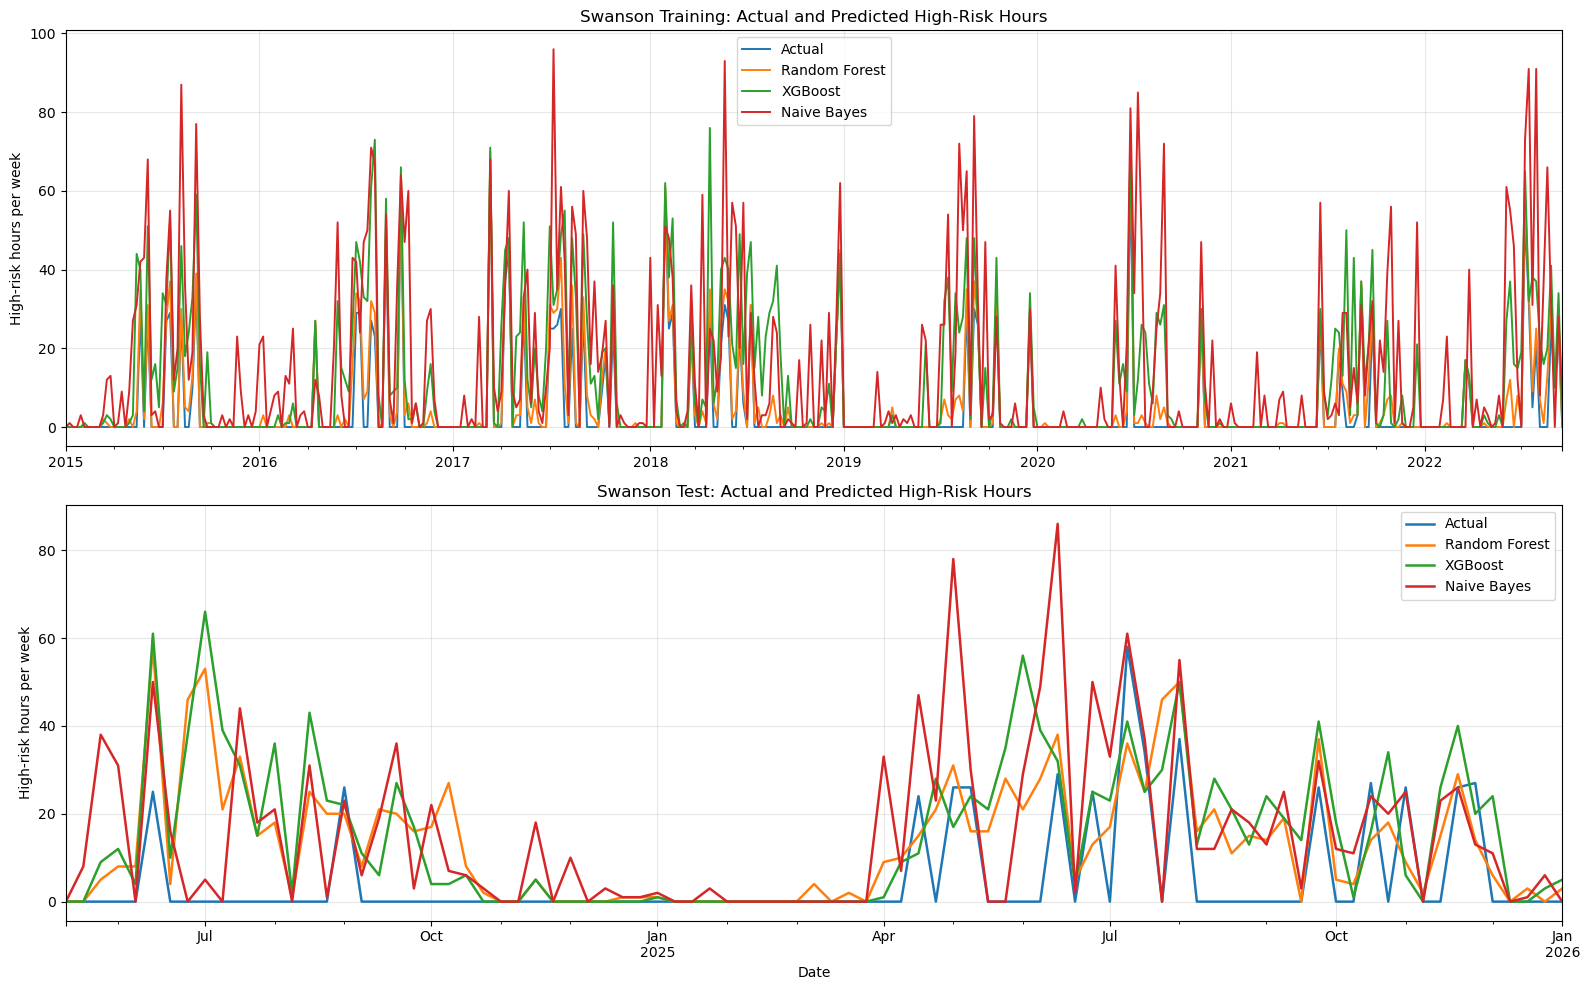

In [65]:
# SWANSON ACTUAL VERSUS THREE MODEL PREDICTIONS

rf_training_prediction = (
    swanson_rf.predict_proba(X_train)[:, 1] >=
    swanson_rf_threshold
).astype(int)

xgb_training_prediction = (
    swanson_xgb.predict_proba(X_train)[:, 1] >=
    swanson_xgb_threshold
).astype(int)

training_model_predictions = pd.DataFrame({
    "timestamp": train_data["timestamp"].to_numpy(),
    "Actual": y_train.to_numpy(),
    "Random Forest": rf_training_prediction,
    "XGBoost": xgb_training_prediction,
    "Naive Bayes": training_prediction_nb
})

training_model_predictions["timestamp"] = pd.to_datetime(
    training_model_predictions["timestamp"]
)

training_model_predictions = (
    training_model_predictions
    .set_index("timestamp")
    .resample("W")
    .sum()
)

test_model_predictions = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Random Forest": rf_test_prediction,
    "XGBoost": xgb_test_prediction,
    "Naive Bayes": test_prediction_nb
})

test_model_predictions["timestamp"] = pd.to_datetime(
    test_model_predictions["timestamp"]
)

test_model_predictions = (
    test_model_predictions
    .set_index("timestamp")
    .resample("W")
    .sum()
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 10)
)

training_model_predictions.plot(
    ax=axes[0],
    linewidth=1.4
)

axes[0].set_title(
    "Swanson Training: Actual and Predicted High-Risk Hours"
)
axes[0].set_xlabel("")
axes[0].set_ylabel("High-risk hours per week")
axes[0].grid(alpha=0.3)
axes[0].legend(title="")

test_model_predictions.plot(
    ax=axes[1],
    linewidth=1.8
)

axes[1].set_title(
    "Swanson Test: Actual and Predicted High-Risk Hours"
)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("High-risk hours per week")
axes[1].grid(alpha=0.3)
axes[1].legend(title="")

plt.tight_layout()
plt.show()

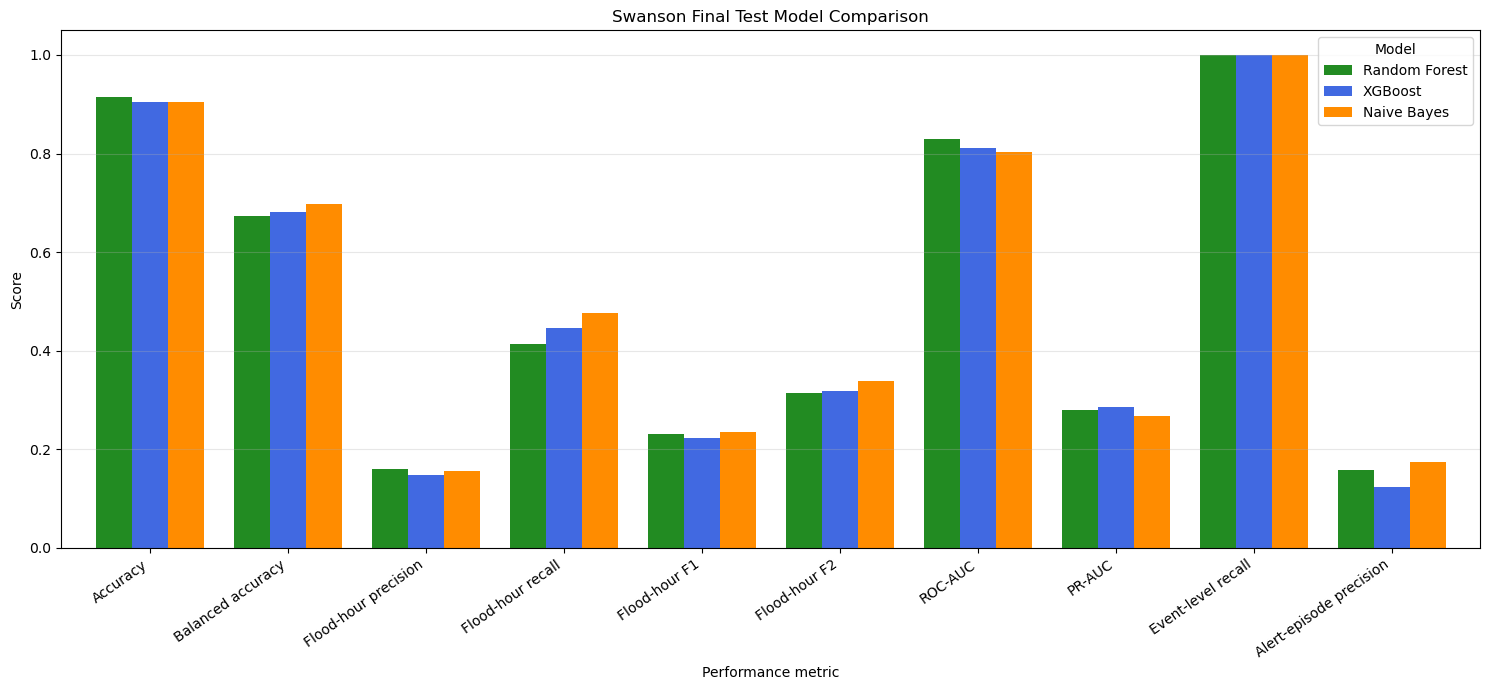

Recommended Swanson model: Gaussian Naive Bayes
Reason: Naive Bayes detected all 15 high-risk events and produced the highest balanced accuracy, recall, F1 and F2. It also produced the fewest false alert episodes and the highest alert-episode precision.


In [66]:
# SWANSON THREE-MODEL PERFORMANCE GRAPH AND RECOMMENDATION

performance_metrics = [
    "Accuracy",
    "Balanced accuracy",
    "Flood-hour precision",
    "Flood-hour recall",
    "Flood-hour F1",
    "Flood-hour F2",
    "ROC-AUC",
    "PR-AUC",
    "Event-level recall",
    "Alert-episode precision"
]

performance_plot = (
    swanson_three_model_test_comparison
    .loc[performance_metrics]
)

ax = performance_plot.plot(
    kind="bar",
    figsize=(15, 7),
    color=["forestgreen", "royalblue", "darkorange"],
    width=0.78
)

ax.set_title("Swanson Final Test Model Comparison")
ax.set_xlabel("Performance metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Recommended Swanson model: Gaussian Naive Bayes")

print(
    "Reason: Naive Bayes detected all 15 high-risk events and "
    "produced the highest balanced accuracy, recall, F1 and F2. "
    "It also produced the fewest false alert episodes and the "
    "highest alert-episode precision."
)

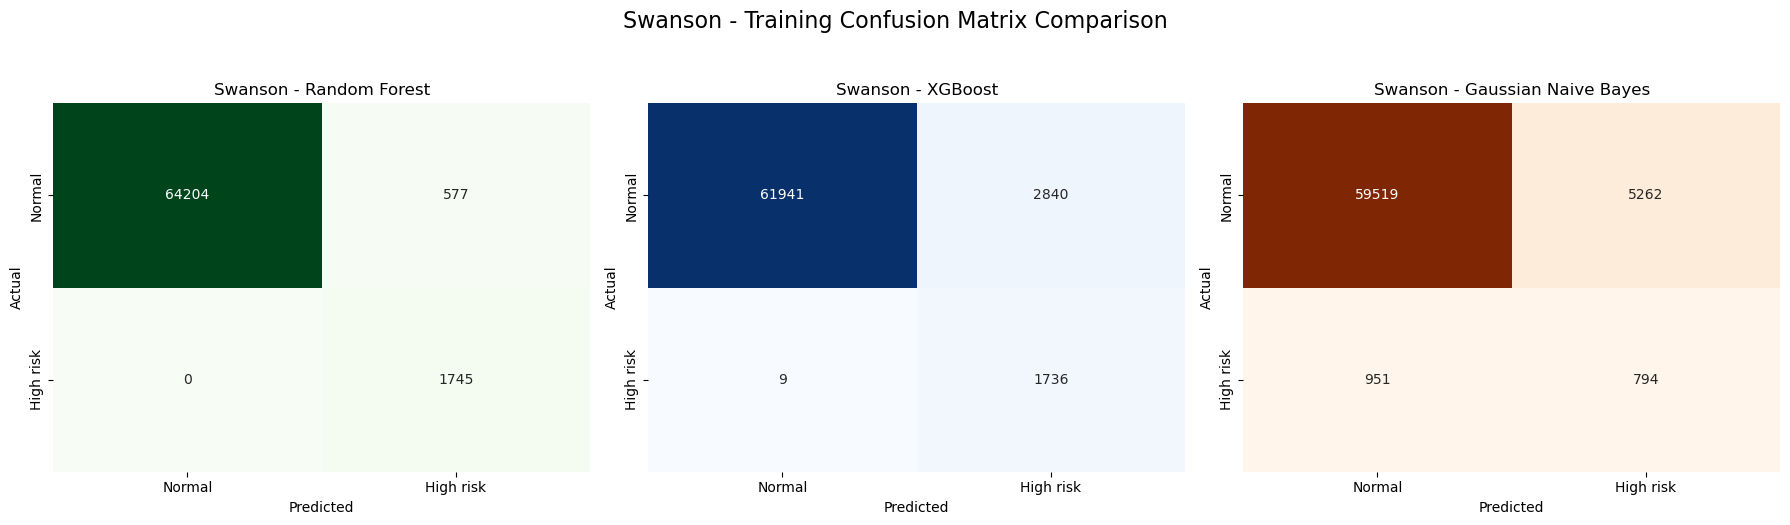

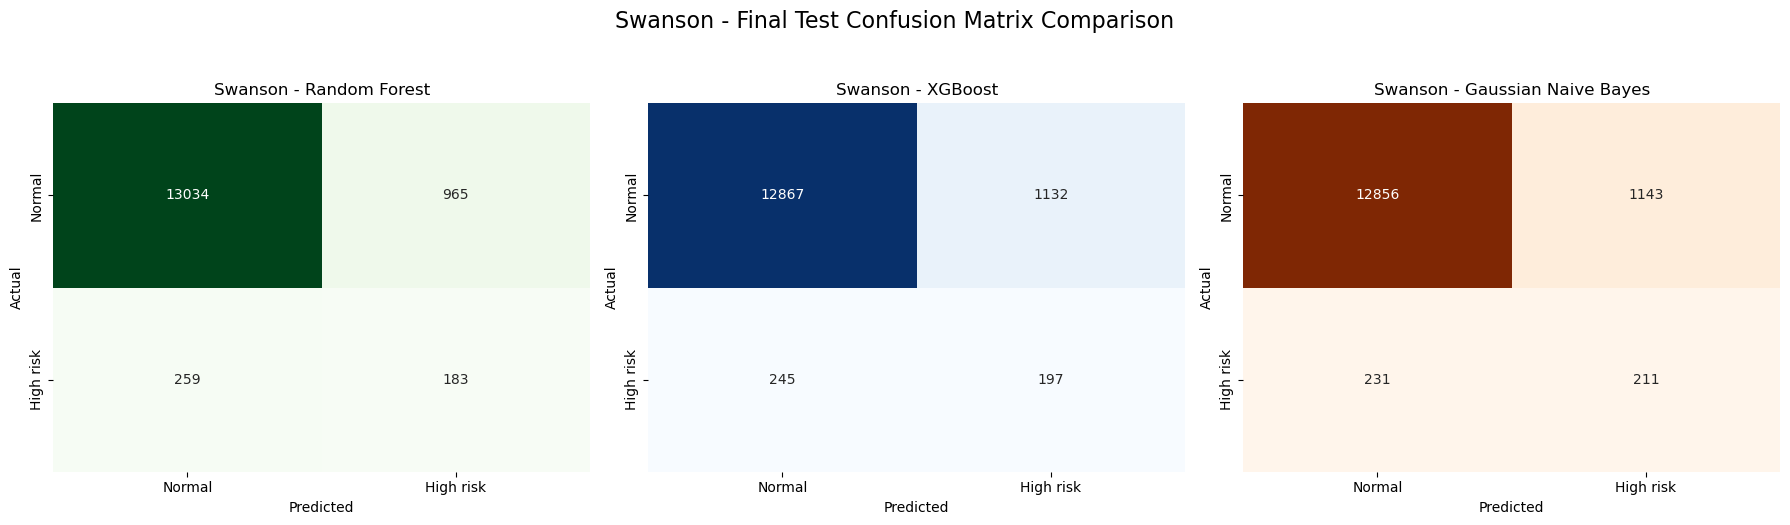

In [75]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Random Forest training predictions
rf_train_prediction = (
    rf_train_probability >= swanson_rf_threshold
).astype(int)

# XGBoost training predictions
xgb_train_prediction = (
    xgb_train_probability >= swanson_xgb_threshold
).astype(int)

# Naive Bayes training and test predictions
nb_train_prediction = training_prediction_nb
nb_test_prediction = test_prediction_nb

training_predictions = {
    "Random Forest": rf_train_prediction,
    "XGBoost": xgb_train_prediction,
    "Gaussian Naive Bayes": nb_train_prediction
}

test_predictions = {
    "Random Forest": rf_test_prediction,
    "XGBoost": xgb_test_prediction,
    "Gaussian Naive Bayes": nb_test_prediction
}

colours = ["Greens", "Blues", "Oranges"]

# Training confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, (model_name, prediction), colour in zip(
    axes, training_predictions.items(), colours
):
    matrix = confusion_matrix(y_train, prediction)

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap=colour,
        cbar=False,
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"],
        ax=axis
    )

    axis.set_title(f"Swanson - {model_name}")
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

plt.suptitle(
    "Swanson - Training Confusion Matrix Comparison",
    fontsize=16,
    y=1.04
)

plt.tight_layout()
plt.show()

# Testing confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, (model_name, prediction), colour in zip(
    axes, test_predictions.items(), colours
):
    matrix = confusion_matrix(y_test, prediction)

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap=colour,
        cbar=False,
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"],
        ax=axis
    )

    axis.set_title(f"Swanson - {model_name}")
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

plt.suptitle(
    "Swanson - Final Test Confusion Matrix Comparison",
    fontsize=16,
    y=1.04
)

plt.tight_layout()
plt.show()

In [76]:
# EXPORT SWANSON NAIVE BAYES AND THREE-MODEL RESULTS

from pathlib import Path
import joblib
import pandas as pd

output_folder = (
    Path.home() /
    "Downloads" /
    "Swanson_Model_Outputs"
)

output_folder.mkdir(parents=True, exist_ok=True)

# Hourly training predictions for all three models
swanson_training_model_predictions = pd.DataFrame({
    "timestamp": train_data["timestamp"].to_numpy(),
    "actual_high_water_risk_24h": y_train.to_numpy(),

    "random_forest_score": rf_train_probability,
    "random_forest_prediction": rf_train_prediction,

    "xgboost_score": xgb_train_probability,
    "xgboost_prediction": xgb_train_prediction,

    "naive_bayes_score": training_probability_nb,
    "naive_bayes_prediction": training_prediction_nb
})

# Hourly test predictions for all three models
swanson_test_model_predictions = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "actual_high_water_risk_24h": y_test.to_numpy(),

    "random_forest_score": rf_test_probability,
    "random_forest_prediction": rf_test_prediction,

    "xgboost_score": xgb_test_probability,
    "xgboost_prediction": xgb_test_prediction,

    "naive_bayes_score": test_probability_nb,
    "naive_bayes_prediction": test_prediction_nb
})

# Save Naive Bayes results
swanson_naive_bayes_tuning_results.to_csv(
    output_folder / "swanson_naive_bayes_tuning_results.csv",
    index=False
)

swanson_naive_bayes_validation_results.to_frame().T.to_csv(
    output_folder / "swanson_naive_bayes_validation_results.csv",
    index=False
)

swanson_naive_bayes_test_results.to_frame().T.to_csv(
    output_folder / "swanson_naive_bayes_test_results.csv",
    index=False
)

swanson_naive_bayes_test_predictions.to_csv(
    output_folder / "swanson_naive_bayes_test_predictions.csv",
    index=False
)

swanson_naive_bayes_event_results.to_csv(
    output_folder / "swanson_naive_bayes_event_results.csv",
    index=False
)

swanson_naive_bayes_event_summary.to_frame().T.to_csv(
    output_folder / "swanson_naive_bayes_event_summary.csv",
    index=False
)

swanson_naive_bayes_alert_results.to_csv(
    output_folder / "swanson_naive_bayes_alert_results.csv",
    index=False
)

swanson_naive_bayes_train_test_comparison.to_csv(
    output_folder / "swanson_naive_bayes_train_test_comparison.csv"
)

# Save three-model comparisons and predictions
swanson_three_model_test_comparison.to_csv(
    output_folder / "swanson_three_model_test_comparison.csv"
)

swanson_training_model_predictions.to_csv(
    output_folder / "swanson_training_model_predictions.csv",
    index=False
)

swanson_test_model_predictions.to_csv(
    output_folder / "swanson_test_model_predictions.csv",
    index=False
)

# Save fitted Naive Bayes model
joblib.dump(
    swanson_naive_bayes_model,
    output_folder / "swanson_naive_bayes_model.joblib"
)

saved_files = [
    "swanson_naive_bayes_tuning_results.csv",
    "swanson_naive_bayes_validation_results.csv",
    "swanson_naive_bayes_test_results.csv",
    "swanson_naive_bayes_test_predictions.csv",
    "swanson_naive_bayes_event_results.csv",
    "swanson_naive_bayes_event_summary.csv",
    "swanson_naive_bayes_alert_results.csv",
    "swanson_naive_bayes_train_test_comparison.csv",
    "swanson_three_model_test_comparison.csv",
    "swanson_training_model_predictions.csv",
    "swanson_test_model_predictions.csv",
    "swanson_naive_bayes_model.joblib"
]

print("Swanson Naive Bayes and comparison outputs saved to:")
print(output_folder)

print("\nSaved files:")

for file_name in saved_files:
    print("-", file_name)

Swanson Naive Bayes and comparison outputs saved to:
C:\Users\kgeet\Downloads\Swanson_Model_Outputs

Saved files:
- swanson_naive_bayes_tuning_results.csv
- swanson_naive_bayes_validation_results.csv
- swanson_naive_bayes_test_results.csv
- swanson_naive_bayes_test_predictions.csv
- swanson_naive_bayes_event_results.csv
- swanson_naive_bayes_event_summary.csv
- swanson_naive_bayes_alert_results.csv
- swanson_naive_bayes_train_test_comparison.csv
- swanson_three_model_test_comparison.csv
- swanson_training_model_predictions.csv
- swanson_test_model_predictions.csv
- swanson_naive_bayes_model.joblib
